###DIABETES PREDICTION USING MACHINE LEARNING

Team Members:
Lasya,
Adarsh,
Abhiram

Base Models:
Decision Tree,
Support Vector Machine,
EDPA

Additional Models:
Logistic Regression,
Random Forest,
Naive Bayes,
Artificial Neural Network

### Importing of libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
pd.set_option('display.max_columns', None)

### loading of dataset

In [2]:
url = "https://raw.githubusercontent.com/npradaschnor/Pima-Indians-Diabetes-Dataset/master/diabetes.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")

Dataset loaded successfully!


### checking of dataset

In [3]:
print("Dataset Shape:", df.shape)

Dataset Shape: (768, 9)


In [4]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [6]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


### checking of missing values

In [7]:
df.isnull().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


In [8]:
print("Column Names:")
print(df.columns.tolist())

Column Names:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']


In [9]:
columns_with_zero = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

for column in columns_with_zero:
    print(column, ":", (df[column] == 0).sum())

Glucose : 5
BloodPressure : 35
SkinThickness : 227
Insulin : 374
BMI : 11


### cleaning dataset

In [10]:
columns_to_clean = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

df[columns_to_clean] = df[columns_to_clean].replace(0, np.nan)

for column in columns_to_clean:
    df[column] = df[column].fillna(df[column].median())

print("Data cleaning completed!")

Data cleaning completed!


In [11]:
print(df.isnull().sum())

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


### checking duplicate values

In [12]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [13]:
df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (768, 9)


### otcome distribution

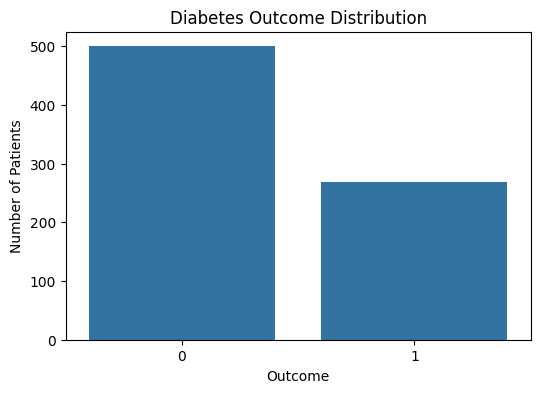

In [14]:
plt.figure(figsize=(6, 4))

sns.countplot(x="Outcome", data=df)

plt.title("Diabetes Outcome Distribution")
plt.xlabel("Outcome")
plt.ylabel("Number of Patients")

plt.show()

### correlation heatmap

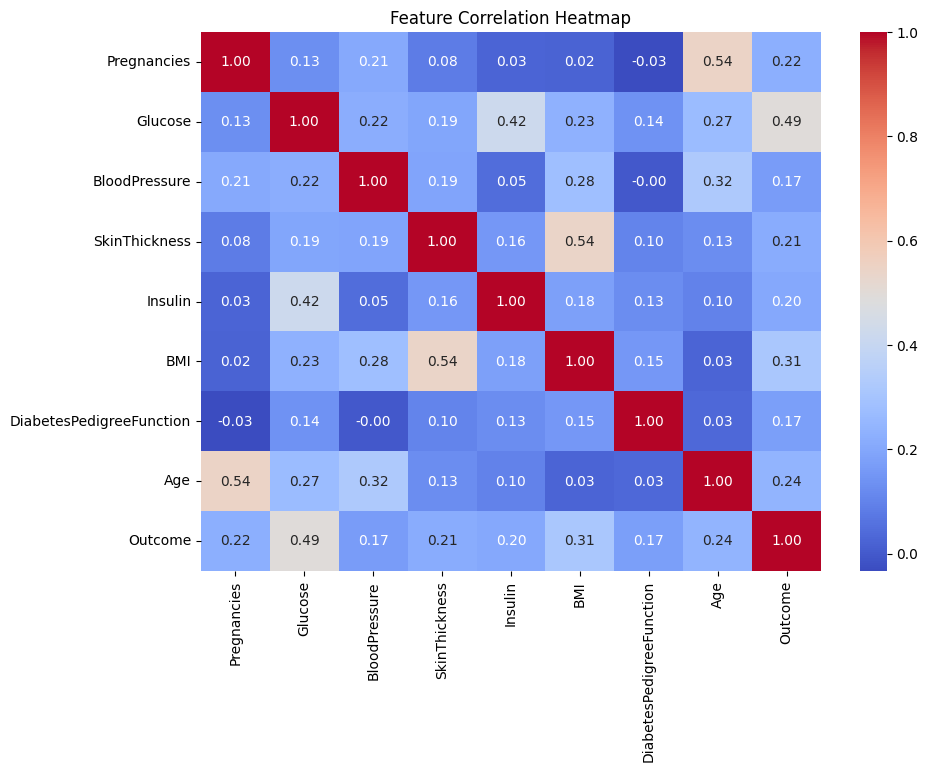

In [15]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Correlation Heatmap")
plt.show()

### feature distribution

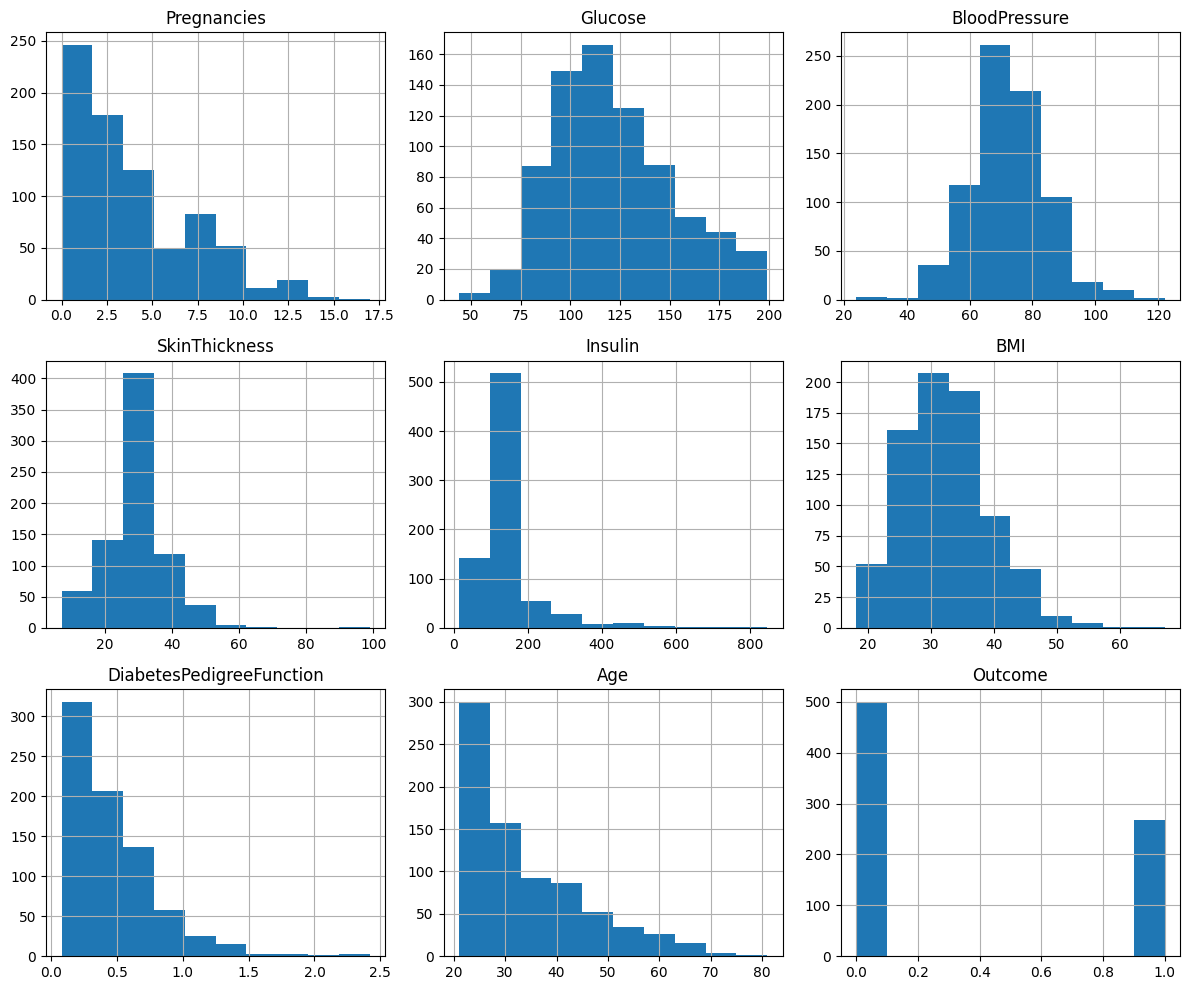

In [16]:
df.hist(figsize=(12, 10))

plt.tight_layout()
plt.show()

### seperate input and output

In [17]:
X = df.drop("Outcome", axis=1)
y = df["Outcome"]

print("Features (X):")
print(X.columns.tolist())

print("\nTarget (y):")
print(y.name)

Features (X):
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']

Target (y):
Outcome


### train and test split

In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (614, 8)
Testing data: (154, 8)


### feature scaling

In [19]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Algorithms
## Decision tree

In [20]:
from sklearn.tree import DecisionTreeClassifier
dt_model = DecisionTreeClassifier(random_state=42)

dt_model.fit(X_train, y_train)

DecisionTreeClassifier(random_state=42)

In [21]:
dt_pred = dt_model.predict(X_test)

print("Decision Tree predictions:")
print(dt_pred)

Decision Tree predictions:
[1 0 0 1 1 0 0 1 0 1 1 1 0 0 0 0 1 0 1 0 0 0 0 0 1 0 1 0 1 0 1 0 1 0 1 0 0
 0 1 0 0 0 0 0 0 0 0 0 1 1 0 1 1 0 0 1 0 0 0 0 0 1 1 1 0 1 1 0 1 1 0 0 0 1
 0 0 0 1 0 0 0 0 0 0 1 0 0 1 0 0 0 1 0 0 1 0 0 0 1 0 0 1 0 0 1 0 0 0 0 0 0
 1 1 0 0 0 0 0 1 0 0 0 0 1 1 1 0 1 0 0 0 1 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0
 0 0 0 0 1 0]


### evaluation of decision tree

In [22]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

dt_accuracy = accuracy_score(y_test, dt_pred)
dt_precision = precision_score(y_test, dt_pred)
dt_recall = recall_score(y_test, dt_pred)
dt_f1 = f1_score(y_test, dt_pred)

print("Decision Tree Results")
print("---------------------")
print("Accuracy :", dt_accuracy)
print("Precision:", dt_precision)
print("Recall   :", dt_recall)
print("F1 Score :", dt_f1)

Decision Tree Results
---------------------
Accuracy : 0.6818181818181818
Precision: 0.5531914893617021
Recall   : 0.48148148148148145
F1 Score : 0.5148514851485149


### confusion matrix for decision tree

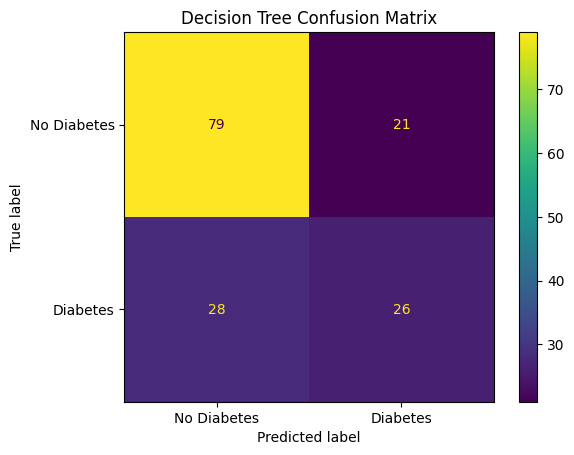

In [23]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, dt_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Diabetes", "Diabetes"]
)

disp.plot()
plt.title("Decision Tree Confusion Matrix")
plt.show()

### ROC-AUC for decision tree

In [24]:
from sklearn.metrics import roc_auc_score

dt_prob = dt_model.predict_proba(X_test)[:, 1]

dt_auc = roc_auc_score(y_test, dt_prob)

print("Decision Tree ROC-AUC:", dt_auc)

Decision Tree ROC-AUC: 0.6357407407407407


### storing the decision tree result

In [25]:
results = []

results.append({
    "Algorithm": "Decision Tree",
    "Accuracy": dt_accuracy,
    "Precision": dt_precision,
    "Recall": dt_recall,
    "F1 Score": dt_f1,
    "ROC-AUC": dt_auc
})

SVM

In [26]:
from sklearn.svm import SVC
svm_model = SVC(probability=True, random_state=42)

svm_model.fit(X_train_scaled, y_train)

print("SVM model trained successfully!")
svm_pred = svm_model.predict(X_test_scaled)

print("SVM predictions:")
print(svm_pred)

SVM model trained successfully!
SVM predictions:
[1 0 0 0 0 0 0 1 0 1 0 0 0 0 0 0 1 0 1 0 0 1 0 1 0 0 1 0 0 0 0 0 0 1 1 0 0
 0 1 1 0 0 0 0 0 0 0 0 1 0 0 1 0 0 1 0 1 0 1 0 1 0 0 1 0 0 1 0 0 1 0 0 0 1
 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 1 1 0 0 0 1 1 1 1 0 0 0 0 0 1 0 1 0 1 0 0
 1 1 0 0 0 0 0 1 0 1 0 0 1 0 1 1 1 0 0 0 1 0 1 1 0 0 0 0 0 0 0 0 0 0 0 1 1
 0 0 0 0 1 0]


In [27]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

svm_accuracy = accuracy_score(y_test, svm_pred)
svm_precision = precision_score(y_test, svm_pred)
svm_recall = recall_score(y_test, svm_pred)
svm_f1 = f1_score(y_test, svm_pred)

svm_prob = svm_model.predict_proba(X_test_scaled)[:, 1]
svm_auc = roc_auc_score(y_test, svm_prob)

print("SVM Results")
print("---------------------")
print("Accuracy :", svm_accuracy)
print("Precision:", svm_precision)
print("Recall   :", svm_recall)
print("F1 Score :", svm_f1)
print("ROC-AUC  :", svm_auc)

SVM Results
---------------------
Accuracy : 0.7402597402597403
Precision: 0.6521739130434783
Recall   : 0.5555555555555556
F1 Score : 0.6
ROC-AUC  : 0.7963888888888889


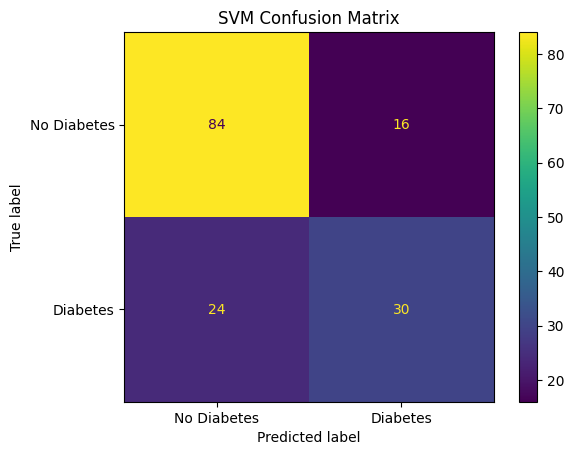

In [28]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, svm_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Diabetes", "Diabetes"]
)

disp.plot()
plt.title("SVM Confusion Matrix")
plt.show()

In [29]:
results.append({
    "Algorithm": "SVM",
    "Accuracy": svm_accuracy,
    "Precision": svm_precision,
    "Recall": svm_recall,
    "F1 Score": svm_f1,
    "ROC-AUC": svm_auc
})

LOGISTIC REGRESSION

In [30]:
from sklearn.linear_model import LogisticRegression
lr_model = LogisticRegression(max_iter=1000, random_state=42)

lr_model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully!")
lr_pred = lr_model.predict(X_test_scaled)

print("Logistic Regression predictions:")
print(lr_pred)

Logistic Regression model trained successfully!
Logistic Regression predictions:
[1 0 0 0 0 0 0 1 0 1 0 0 0 0 0 0 1 0 1 0 0 1 0 1 1 0 1 0 0 0 0 0 0 1 1 0 0
 0 1 1 0 0 0 0 0 0 0 0 1 0 1 1 0 0 1 0 1 0 1 0 1 0 0 1 0 0 1 0 0 1 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0 1 1 0 1 1 0 0 0 0 0 1 0 1 0 1 0 1
 1 0 0 0 0 0 0 1 0 1 0 0 1 0 1 1 1 0 0 0 1 0 1 1 0 0 0 0 0 0 0 0 0 0 0 0 1
 0 0 0 0 1 0]


In [31]:
lr_accuracy = accuracy_score(y_test, lr_pred)
lr_precision = precision_score(y_test, lr_pred)
lr_recall = recall_score(y_test, lr_pred)
lr_f1 = f1_score(y_test, lr_pred)

lr_prob = lr_model.predict_proba(X_test_scaled)[:, 1]
lr_auc = roc_auc_score(y_test, lr_prob)

print("Logistic Regression Results")
print("---------------------------")
print("Accuracy :", lr_accuracy)
print("Precision:", lr_precision)
print("Recall   :", lr_recall)
print("F1 Score :", lr_f1)
print("ROC-AUC  :", lr_auc)

Logistic Regression Results
---------------------------
Accuracy : 0.7077922077922078
Precision: 0.6
Recall   : 0.5
F1 Score : 0.5454545454545454
ROC-AUC  : 0.812962962962963


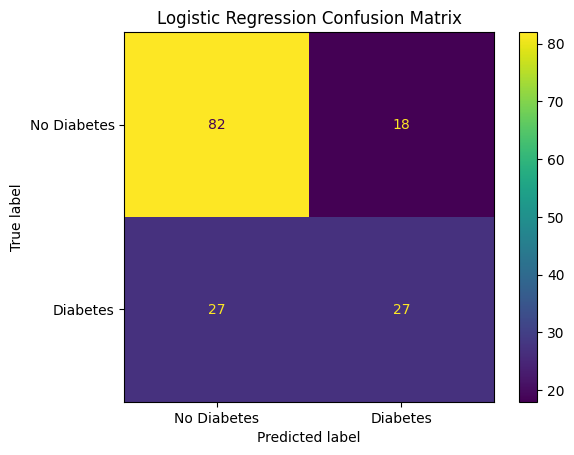

In [32]:
cm = confusion_matrix(y_test, lr_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Diabetes", "Diabetes"]
)

disp.plot()
plt.title("Logistic Regression Confusion Matrix")
plt.show()

In [33]:
results.append({
    "Algorithm": "Logistic Regression",
    "Accuracy": lr_accuracy,
    "Precision": lr_precision,
    "Recall": lr_recall,
    "F1 Score": lr_f1,
    "ROC-AUC": lr_auc
})

RANDOM FOREST

In [34]:
from sklearn.ensemble import RandomForestClassifier
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")
rf_pred = rf_model.predict(X_test)

print("Random Forest predictions:")
print(rf_pred)

Random Forest model trained successfully!
Random Forest predictions:
[1 0 0 0 0 0 1 1 0 1 0 1 0 0 0 0 1 0 1 0 0 1 0 1 0 0 1 0 1 0 0 0 1 0 1 0 0
 0 1 0 0 0 0 0 0 0 0 0 1 0 0 1 0 0 0 0 1 0 1 0 1 0 0 1 0 1 1 0 0 1 0 0 0 1
 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 1 1 0 0 0 0 1 0 1 0 0 0 0 0 1 0 1 0 1 0 0
 1 1 0 0 0 0 0 1 0 1 0 0 0 0 1 1 0 0 0 0 1 0 1 1 0 0 0 0 0 0 0 0 0 0 0 1 1
 0 0 0 0 1 0]


In [35]:
rf_accuracy = accuracy_score(y_test, rf_pred)
rf_precision = precision_score(y_test, rf_pred)
rf_recall = recall_score(y_test, rf_pred)
rf_f1 = f1_score(y_test, rf_pred)

rf_prob = rf_model.predict_proba(X_test)[:, 1]
rf_auc = roc_auc_score(y_test, rf_prob)

print("Random Forest Results")
print("---------------------")
print("Accuracy :", rf_accuracy)
print("Precision:", rf_precision)
print("Recall   :", rf_recall)
print("F1 Score :", rf_f1)
print("ROC-AUC  :", rf_auc)

Random Forest Results
---------------------
Accuracy : 0.7792207792207793
Precision: 0.7272727272727273
Recall   : 0.5925925925925926
F1 Score : 0.6530612244897959
ROC-AUC  : 0.8191666666666666


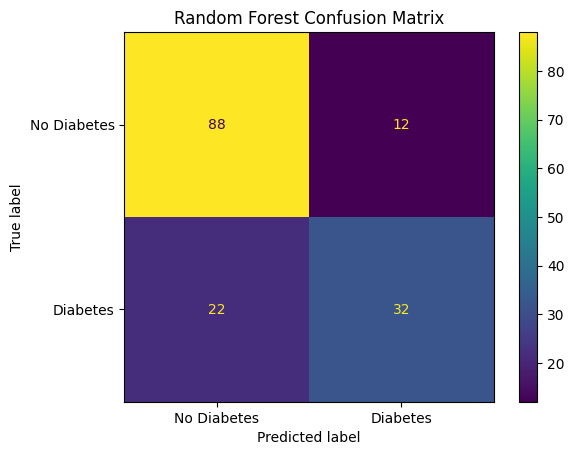

In [36]:
cm = confusion_matrix(y_test, rf_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Diabetes", "Diabetes"]
)

disp.plot()
plt.title("Random Forest Confusion Matrix")
plt.show()

In [37]:
results.append({
    "Algorithm": "Random Forest",
    "Accuracy": rf_accuracy,
    "Precision": rf_precision,
    "Recall": rf_recall,
    "F1 Score": rf_f1,
    "ROC-AUC": rf_auc
})

Naive bayes

In [38]:
from sklearn.naive_bayes import GaussianNB
nb_model = GaussianNB()

nb_model.fit(X_train_scaled, y_train)

print("Naive Bayes model trained successfully!")
nb_pred = nb_model.predict(X_test_scaled)

print("Naive Bayes predictions:")
print(nb_pred)

Naive Bayes model trained successfully!
Naive Bayes predictions:
[1 0 0 0 0 0 1 1 0 1 0 0 0 1 0 0 1 0 1 0 0 1 0 1 1 0 1 0 0 0 0 0 0 1 1 0 0
 0 1 1 1 0 0 0 0 0 0 0 1 0 1 1 1 0 1 0 1 0 1 0 1 0 0 1 0 0 1 0 0 1 0 0 0 1
 0 0 0 1 0 0 0 0 0 0 0 0 0 1 0 1 1 1 0 0 1 1 1 1 1 0 0 0 1 0 1 0 1 0 1 1 1
 1 1 0 0 0 1 0 1 0 1 0 0 1 0 1 1 0 0 0 0 1 0 1 1 0 0 0 0 0 0 1 0 0 0 0 1 1
 1 0 0 0 1 0]


In [39]:
nb_accuracy = accuracy_score(y_test, nb_pred)
nb_precision = precision_score(y_test, nb_pred)
nb_recall = recall_score(y_test, nb_pred)
nb_f1 = f1_score(y_test, nb_pred)

nb_prob = nb_model.predict_proba(X_test_scaled)[:, 1]
nb_auc = roc_auc_score(y_test, nb_prob)

print("Naive Bayes Results")
print("-------------------")
print("Accuracy :", nb_accuracy)
print("Precision:", nb_precision)
print("Recall   :", nb_recall)
print("F1 Score :", nb_f1)
print("ROC-AUC  :", nb_auc)

Naive Bayes Results
-------------------
Accuracy : 0.7012987012987013
Precision: 0.5666666666666667
Recall   : 0.6296296296296297
F1 Score : 0.5964912280701754
ROC-AUC  : 0.7646296296296297


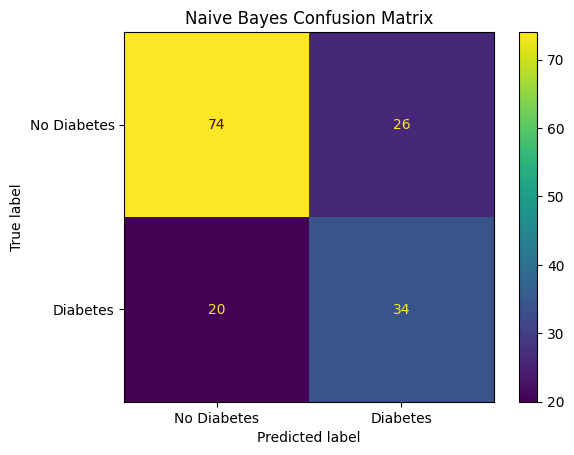

In [40]:
cm = confusion_matrix(y_test, nb_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Diabetes", "Diabetes"]
)

disp.plot()
plt.title("Naive Bayes Confusion Matrix")
plt.show()

In [41]:
results.append({
    "Algorithm": "Naive Bayes",
    "Accuracy": nb_accuracy,
    "Precision": nb_precision,
    "Recall": nb_recall,
    "F1 Score": nb_f1,
    "ROC-AUC": nb_auc
})

ANN(Artificial Neural Network)

In [42]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout

print("TensorFlow version:", tf.__version__)

ann_model = Sequential([
    Input(shape=(X_train_scaled.shape[1],)),
    Dense(32, activation="relu"),
    Dropout(0.15),
    Dense(16, activation="relu"),
    Dropout(0.15),
    Dense(1, activation="sigmoid")
])

ann_model.summary()


TensorFlow version: 2.20.0


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 833 (3.25 KB)

 Trainable params: 833 (3.25 KB)

 Non-trainable params: 0 (0.00 B)

In [43]:
ann_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("ANN compiled successfully!")

ANN compiled successfully!


In [44]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=15,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=7,
    min_lr=1e-5,
    verbose=1
)

history = ann_model.fit(
    X_train_scaled,
    y_train,
    epochs=150,
    batch_size=16,
    validation_split=0.2,
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)


Epoch 1/150
31/31 ━━━━━━━━━━━━━━━━━━━━ 7s 34ms/step - accuracy: 0.6314 - loss: 0.6662 - val_accuracy: 0.7236 - val_loss: 0.6212 - learning_rate: 0.0010
Epoch 2/150
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.7047 - loss: 0.6162 - val_accuracy: 0.7724 - val_loss: 0.5646 - learning_rate: 0.0010
Epoch 3/150
31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.7454 - loss: 0.5586 - val_accuracy: 0.7886 - val_loss: 0.5258 - learning_rate: 0.0010
Epoch 4/150
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.7515 - loss: 0.5211 - val_accuracy: 0.8049 - val_loss: 0.4939 - learning_rate: 0.0010
Epoch 5/150
31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.7556 - loss: 0.4943 - val_accuracy: 0.7967 - val_loss: 0.4707 - learning_rate: 0.0010
Epoch 6/150
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7739 - loss: 0.4938 - val_accuracy: 0.7886 - val_loss: 0.4583 - learning_rate: 0.0010
Epoch 7/150
31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.7699 - loss: 0.4622 - 

In [45]:
ann_prob = ann_model.predict(X_test_scaled)

ann_pred = (ann_prob >= 0.5).astype(int).ravel()

print("ANN predictions:")
print(ann_pred)

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
ANN predictions:
[1 0 0 0 0 0 0 1 0 1 0 0 0 0 0 0 1 0 1 0 0 1 0 1 1 0 1 0 0 0 0 0 1 0 1 0 0
 0 1 1 0 0 0 0 0 0 0 0 1 0 1 1 0 0 1 0 1 0 1 0 1 0 0 1 0 0 1 0 0 1 0 0 0 1
 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 1 1 0 0 1 1 0 1 1 0 0 0 0 0 1 0 1 0 1 0 1
 1 0 0 0 0 0 0 1 0 0 0 0 1 0 1 1 1 0 0 0 1 0 1 1 0 0 0 0 0 0 0 0 0 0 0 1 1
 1 0 0 0 1 0]


In [46]:
ann_accuracy = accuracy_score(y_test, ann_pred)
ann_precision = precision_score(y_test, ann_pred)
ann_recall = recall_score(y_test, ann_pred)
ann_f1 = f1_score(y_test, ann_pred)

ann_auc = roc_auc_score(y_test, ann_prob.ravel())

print("ANN Results")
print("---------------------")
print("Accuracy :", ann_accuracy)
print("Precision:", ann_precision)
print("Recall   :", ann_recall)
print("F1 Score :", ann_f1)
print("ROC-AUC  :", ann_auc)

ANN Results
---------------------
Accuracy : 0.7272727272727273
Precision: 0.625
Recall   : 0.5555555555555556
F1 Score : 0.5882352941176471
ROC-AUC  : 0.8087037037037037


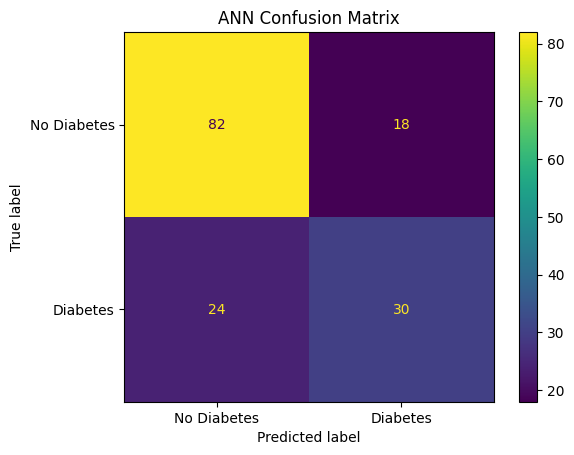

In [47]:
cm = confusion_matrix(y_test, ann_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Diabetes", "Diabetes"]
)

disp.plot()
plt.title("ANN Confusion Matrix")
plt.show()

In [48]:
results.append({
    "Algorithm": "ANN",
    "Accuracy": ann_accuracy,
    "Precision": ann_precision,
    "Recall": ann_recall,
    "F1 Score": ann_f1,
    "ROC-AUC": ann_auc
})

Comparison Table

In [49]:
results_df = pd.DataFrame(results)

results_df

,Algorithm,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Decision Tree,0.681818,0.553191,0.481481,0.514851,0.635741
1,SVM,0.740260,0.652174,0.555556,0.600000,0.796389
2,Logistic Regression,0.707792,0.600000,0.500000,0.545455,0.812963
3,Random Forest,0.779221,0.727273,0.592593,0.653061,0.819167
4,Naive Bayes,0.701299,0.566667,0.629630,0.596491,0.764630
5,ANN,0.727273,0.625000,0.555556,0.588235,0.808704


Best algorithm

In [50]:
best_model = results_df.loc[results_df["Accuracy"].idxmax()]

print("===================================")
print("       BEST ALGORITHM")
print("===================================")
print("Algorithm :", best_model["Algorithm"])
print("Accuracy  :", round(best_model["Accuracy"] * 100, 2), "%")
print("Precision :", round(best_model["Precision"] * 100, 2), "%")
print("Recall    :", round(best_model["Recall"] * 100, 2), "%")
print("F1 Score  :", round(best_model["F1 Score"] * 100, 2), "%")
print("ROC-AUC   :", round(best_model["ROC-AUC"], 4))
print("===================================")

       BEST ALGORITHM
Algorithm : Random Forest
Accuracy  : 77.92 %
Precision : 72.73 %
Recall    : 59.26 %
F1 Score  : 65.31 %
ROC-AUC   : 0.8192


predictions

In [51]:
prediction_df = pd.DataFrame({
    "Actual": y_test.values,
    "Decision Tree": dt_pred,
    "SVM": svm_pred,
    "Logistic Regression": lr_pred,
    "Random Forest": rf_pred,
    "Naive Bayes": nb_pred,
    "ANN": ann_pred
})

prediction_df.index = range(1, len(prediction_df) + 1)

prediction_df.head(20)

,Actual,Decision Tree,SVM,Logistic Regression,Random Forest,Naive Bayes,ANN
1,0,1,1,1,1,1,1
2,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0
4,1,1,0,0,0,0,0
5,0,1,0,0,0,0,0
6,0,0,0,0,0,0,0
7,1,0,0,0,1,1,0
8,1,1,1,1,1,1,1
9,0,0,0,0,0,0,0
10,0,1,1,1,1,1,1


In [52]:
best_algorithm = best_model["Algorithm"]

prediction_columns = {
    "Decision Tree": dt_pred,
    "SVM": svm_pred,
    "Logistic Regression": lr_pred,
    "Random Forest": rf_pred,
    "Naive Bayes": nb_pred,
    "ANN": ann_pred
}

best_predictions = prediction_columns[best_algorithm]

best_prediction_df = pd.DataFrame({
    "Patient": range(1, len(y_test) + 1),
    "Actual": y_test.values,
    "Predicted": best_predictions
})

print("Best Algorithm:", best_algorithm)
print()

display(best_prediction_df.head(20))

Best Algorithm: Random Forest



,Patient,Actual,Predicted
0,1,0,1
1,2,0,0
2,3,0,0
3,4,1,0
4,5,0,0
5,6,0,0
6,7,1,1
7,8,1,1
8,9,0,0
9,10,0,1


In [53]:
for i in range(10):
    actual = y_test.values[i]
    predicted = best_predictions[i]

    actual_text = "Diabetic" if actual == 1 else "Non-Diabetic"
    predicted_text = "Diabetic" if predicted == 1 else "Non-Diabetic"

    print(
        f"Patient {i+1}: "
        f"Actual = {actual_text}, "
        f"Predicted = {predicted_text}"
    )

Patient 1: Actual = Non-Diabetic, Predicted = Diabetic
Patient 2: Actual = Non-Diabetic, Predicted = Non-Diabetic
Patient 3: Actual = Non-Diabetic, Predicted = Non-Diabetic
Patient 4: Actual = Diabetic, Predicted = Non-Diabetic
Patient 5: Actual = Non-Diabetic, Predicted = Non-Diabetic
Patient 6: Actual = Non-Diabetic, Predicted = Non-Diabetic
Patient 7: Actual = Diabetic, Predicted = Diabetic
Patient 8: Actual = Diabetic, Predicted = Diabetic
Patient 9: Actual = Non-Diabetic, Predicted = Non-Diabetic
Patient 10: Actual = Non-Diabetic, Predicted = Diabetic


# HYBRID / ENSEMBLE MODELS
 HYBRID MODEL 1
 Decision Tree + Random Forest -> Hard Voting

In [54]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.metrics import accuracy_score, classification_report

In [55]:
dt_h1 = DecisionTreeClassifier(random_state=42)

rf_h1 = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

In [56]:
hybrid1 = VotingClassifier(
    estimators=[
        ('dt', dt_h1),
        ('rf', rf_h1)
    ],
    voting='hard'
)

In [57]:
hybrid1.fit(X_train_scaled, y_train)

VotingClassifier(estimators=[('dt', DecisionTreeClassifier(random_state=42)),
                             ('rf', RandomForestClassifier(random_state=42))])

In [58]:
hybrid1_pred = hybrid1.predict(X_test_scaled)

print("Hybrid 1 Predictions:")
print(hybrid1_pred)

Hybrid 1 Predictions:
[1 0 0 0 0 0 0 1 0 1 0 1 0 0 0 0 1 0 1 0 0 0 0 0 0 0 1 0 1 0 0 0 1 0 1 0 0
 0 1 0 0 0 0 0 0 0 0 0 1 0 0 1 0 0 0 0 0 0 0 0 0 0 0 1 0 1 1 0 0 1 0 0 0 1
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 1 0 0 0 0 0 1 0 0 0 0 0 0
 1 1 0 0 0 0 0 1 0 0 0 0 0 0 1 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 1 0]


In [59]:
hybrid1_accuracy = accuracy_score(y_test, hybrid1_pred)

print("Hybrid 1 - Decision Tree + Random Forest")
print("Accuracy:", hybrid1_accuracy)

Hybrid 1 - Decision Tree + Random Forest
Accuracy: 0.7207792207792207


In [60]:
print("Classification Report:")
print(classification_report(y_test, hybrid1_pred))

Classification Report:
              precision    recall  f1-score   support

           0       0.72      0.92      0.81       100
           1       0.70      0.35      0.47        54

    accuracy                           0.72       154
   macro avg       0.71      0.64      0.64       154
weighted avg       0.72      0.72      0.69       154



HYBRID MODEL 2

SVM + Logistic Regression + ANN -> Soft Probability Voting

In [61]:
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

In [62]:
svm_h2 = SVC(
    probability=True,
    random_state=42
)

In [63]:
lr_h2 = LogisticRegression(
    max_iter=1000,
    random_state=42
)

In [64]:
svm_h2.fit(X_train_scaled, y_train)

print("SVM trained successfully!")

SVM trained successfully!


In [65]:
lr_h2.fit(X_train_scaled, y_train)

print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


In [66]:
svm_prob_h2 = svm_h2.predict_proba(X_test_scaled)[:, 1]

print("SVM probabilities:")
print(svm_prob_h2)

SVM probabilities:
[0.68687848 0.16081395 0.19615114 0.37492715 0.12841728 0.27003963
 0.395771   0.81455357 0.08269337 0.83833767 0.22120379 0.42847982
 0.1525657  0.18597005 0.12651961 0.29868698 0.69319091 0.09132211
 0.90509918 0.17247695 0.22427827 0.51175422 0.16363945 0.72688053
 0.41342    0.17714892 0.55960041 0.09602026 0.2288243  0.11047794
 0.12410411 0.10862255 0.48714965 0.64845485 0.89663757 0.135602
 0.21884817 0.11125523 0.76524455 0.5        0.31923993 0.31258679
 0.11737038 0.2203294  0.22643578 0.25144993 0.14370806 0.11462212
 0.57685377 0.21342924 0.40899749 0.7751471  0.3425751  0.10081808
 0.51289109 0.31618037 0.73796939 0.19109187 0.81786241 0.10711964
 0.75240236 0.23920859 0.1056473  0.89268597 0.10038467 0.28483197
 0.90889928 0.12518279 0.3736555  0.72954338 0.1526963  0.12274647
 0.24879904 0.54233038 0.1131315  0.40481975 0.09426309 0.42157378
 0.12533925 0.12988115 0.10825185 0.27536703 0.0995848  0.29921387
 0.22761704 0.15824166 0.60965478 0.24194955 

In [67]:
lr_prob_h2 = lr_h2.predict_proba(X_test_scaled)[:, 1]

print("Logistic Regression probabilities:")
print(lr_prob_h2)

Logistic Regression probabilities:
[0.60971073 0.11835576 0.29346313 0.2508367  0.03320667 0.16852385
 0.4881643  0.92367511 0.08143405 0.8385896  0.28100626 0.47973196
 0.12921314 0.10175985 0.28851828 0.35227573 0.72325641 0.08448898
 0.81325928 0.10884945 0.14802102 0.71471974 0.17371866 0.92859352
 0.55003492 0.01217621 0.63475159 0.04314542 0.31193468 0.03711955
 0.04560925 0.03937078 0.47670948 0.64523701 0.88415021 0.13736973
 0.35113095 0.06002771 0.78817394 0.61806144 0.29346001 0.09871885
 0.08791545 0.27794958 0.14650099 0.41265446 0.13320035 0.10278667
 0.68518513 0.34503542 0.62690183 0.70872305 0.44573745 0.06196196
 0.51094031 0.36335073 0.75158091 0.21518922 0.77655756 0.14404703
 0.81520291 0.22254649 0.0488158  0.89481053 0.03379647 0.16089757
 0.89768256 0.01616765 0.26487675 0.67389824 0.18409188 0.09859425
 0.35288121 0.41196442 0.03403222 0.34205538 0.06146412 0.40492574
 0.1195324  0.06407597 0.03265455 0.36711655 0.05362281 0.23985236
 0.11010258 0.11928501 0.40

In [68]:
ann_prob_h2 = ann_model.predict(X_test_scaled)

ann_prob_h2 = ann_prob_h2.ravel()

print("ANN probabilities:")
print(ann_prob_h2)

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 
ANN probabilities:
[0.602439   0.07736802 0.32187638 0.32308307 0.01411714 0.24627179
 0.39992025 0.8382343  0.03480498 0.85889715 0.30703393 0.4990381
 0.04963951 0.03638011 0.14612524 0.42450723 0.6896637  0.02140233
 0.84167516 0.1287716  0.14767827 0.813701   0.16603465 0.8764405
 0.55552953 0.0132574  0.74963605 0.01503041 0.34172535 0.01014671
 0.01136025 0.01275807 0.6515037  0.43342263 0.8560597  0.08844943
 0.3486475  0.03005244 0.6715294  0.5838559  0.353641   0.17072842
 0.03208788 0.23181337 0.09165828 0.4265995  0.08201192 0.08232695
 0.5022709  0.3069707  0.5826272  0.7507861  0.40688983 0.02404673
 0.6226732  0.31537604 0.7448812  0.2516108  0.78385186 0.10389132
 0.8158448  0.17384793 0.02398871 0.8828107  0.0081364  0.33704308
 0.9168915  0.00704699 0.30021927 0.718559   0.09125443 0.03707109
 0.47938043 0.5819704  0.01207576 0.3451856  0.01741331 0.4623832
 0.08649196 0.02089713 0.01213789 0.47591466 0.02648982 0.21247649
 0.14962

In [69]:
hybrid2_prob = (
    svm_prob_h2 +
    lr_prob_h2 +
    ann_prob_h2
) / 3

print("Hybrid 2 probabilities:")
print(hybrid2_prob)

Hybrid 2 probabilities:
[0.6330094  0.11884591 0.27049688 0.31628231 0.05858037 0.22827842
 0.42795185 0.85882099 0.0663108  0.84527481 0.26974799 0.46908329
 0.11047278 0.10803667 0.18705438 0.35848998 0.70203701 0.06573781
 0.85334454 0.13669933 0.17332585 0.68005831 0.16779759 0.84397153
 0.50632815 0.06752751 0.64799602 0.0513987  0.29416144 0.0525814
 0.06035787 0.0535838  0.53845427 0.57570483 0.87894915 0.12047372
 0.30620888 0.06711179 0.7416493  0.56730579 0.32211365 0.19401135
 0.07912457 0.24336412 0.15486502 0.36356796 0.11964011 0.09991191
 0.58810326 0.28847845 0.53950883 0.74488542 0.39840079 0.06227559
 0.54883487 0.33163571 0.7448105  0.21929729 0.79275728 0.11835266
 0.79448335 0.21186767 0.05948393 0.8901024  0.04743918 0.26092421
 0.90782445 0.04946581 0.31291717 0.70733355 0.14268087 0.08613727
 0.36035356 0.5120884  0.05307983 0.36402024 0.05771351 0.42962758
 0.11045454 0.07161808 0.05101476 0.37279941 0.05989914 0.25051424
 0.16244955 0.11295436 0.50071458 0.388

In [70]:
hybrid2_pred = (hybrid2_prob >= 0.5).astype(int)

print("Hybrid 2 Predictions:")
print(hybrid2_pred)

Hybrid 2 Predictions:
[1 0 0 0 0 0 0 1 0 1 0 0 0 0 0 0 1 0 1 0 0 1 0 1 1 0 1 0 0 0 0 0 1 1 1 0 0
 0 1 1 0 0 0 0 0 0 0 0 1 0 1 1 0 0 1 0 1 0 1 0 1 0 0 1 0 0 1 0 0 1 0 0 0 1
 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 1 1 0 0 0 1 1 1 1 0 0 0 0 0 1 0 1 0 1 0 0
 1 0 0 0 0 0 0 1 0 1 0 0 1 0 1 1 1 0 0 0 1 0 1 1 0 0 0 0 0 0 0 0 0 0 0 0 1
 1 0 0 0 1 0]


In [71]:
hybrid2_accuracy = accuracy_score(
    y_test,
    hybrid2_pred
)

print("Hybrid 2 - SVM + Logistic Regression + ANN")
print("Accuracy:", hybrid2_accuracy)

Hybrid 2 - SVM + Logistic Regression + ANN
Accuracy: 0.7012987012987013


In [72]:
print("Classification Report:")
print(classification_report(y_test, hybrid2_pred))

Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.80      0.78       100
           1       0.58      0.52      0.55        54

    accuracy                           0.70       154
   macro avg       0.67      0.66      0.66       154
weighted avg       0.69      0.70      0.70       154



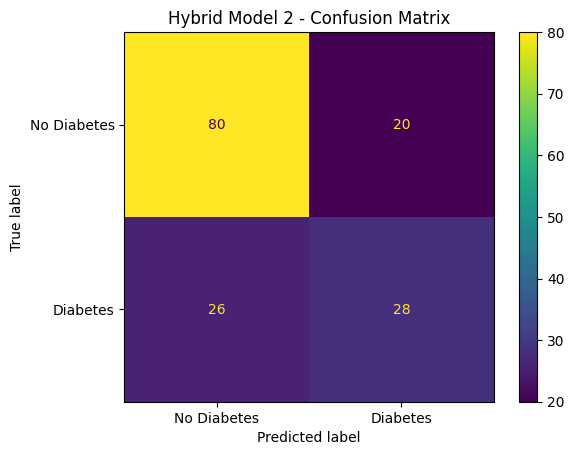

In [73]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm_h2 = confusion_matrix(y_test, hybrid2_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_h2,
    display_labels=["No Diabetes", "Diabetes"]
)

disp.plot()
plt.title("Hybrid Model 2 - Confusion Matrix")
plt.show()

In [74]:
from sklearn.metrics import roc_auc_score

hybrid2_auc = roc_auc_score(
    y_test,
    hybrid2_prob
)

print("Hybrid 2 ROC-AUC:", hybrid2_auc)

Hybrid 2 ROC-AUC: 0.8118518518518518


 HYBRID MODEL 3

Random Forest + SVM + Naive Bayes + ANN

 Weighted Soft Voting

In [75]:

rf_h3 = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

svm_h3 = SVC(
    probability=True,
    random_state=42
)

nb_h3 = GaussianNB()

# Train the models
rf_h3.fit(X_train_scaled, y_train)
svm_h3.fit(X_train_scaled, y_train)
nb_h3.fit(X_train_scaled, y_train)

# Get probabilities for Diabetes (class 1)
rf_prob_h3 = rf_h3.predict_proba(X_test_scaled)[:, 1]

svm_prob_h3 = svm_h3.predict_proba(X_test_scaled)[:, 1]

nb_prob_h3 = nb_h3.predict_proba(X_test_scaled)[:, 1]

# ANN probability
ann_prob_h3 = ann_model.predict(
    X_test_scaled,
    verbose=0
).ravel()


hybrid3_prob = (
    2 * rf_prob_h3 +
    2 * svm_prob_h3 +
    1 * nb_prob_h3 +
    2 * ann_prob_h3
) / 7

# Convert probability into final class
hybrid3_pred = (hybrid3_prob >= 0.5).astype(int)

# ------------------------------------------------------------
# Evaluation
# ------------------------------------------------------------

print("Hybrid 3 - Random Forest + SVM + Naive Bayes + ANN")
print("Accuracy:", accuracy_score(y_test, hybrid3_pred))

print("\nClassification Report:")
print(classification_report(y_test, hybrid3_pred))

Hybrid 3 - Random Forest + SVM + Naive Bayes + ANN
Accuracy: 0.7272727272727273

Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.81      0.79       100
           1       0.62      0.57      0.60        54

    accuracy                           0.73       154
   macro avg       0.70      0.69      0.70       154
weighted avg       0.72      0.73      0.72       154



 HYBRID MODEL 4

 DT + SVM + LR + RF + NB + ANN

 Stacking-style Probability Ensemble

In [76]:


dt_h4 = DecisionTreeClassifier(
    random_state=42
)

svm_h4 = SVC(
    probability=True,
    random_state=42
)

lr_h4 = LogisticRegression(
    max_iter=1000,
    random_state=42
)

rf_h4 = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

nb_h4 = GaussianNB()

# ------------------------------------------------------------
# Train all models
# ------------------------------------------------------------

dt_h4.fit(X_train_scaled, y_train)
svm_h4.fit(X_train_scaled, y_train)
lr_h4.fit(X_train_scaled, y_train)
rf_h4.fit(X_train_scaled, y_train)
nb_h4.fit(X_train_scaled, y_train)

# ------------------------------------------------------------
# Get probabilities for Diabetes (class 1)
# ------------------------------------------------------------

dt_prob_h4 = dt_h4.predict_proba(X_test_scaled)[:, 1]

svm_prob_h4 = svm_h4.predict_proba(X_test_scaled)[:, 1]

lr_prob_h4 = lr_h4.predict_proba(X_test_scaled)[:, 1]

rf_prob_h4 = rf_h4.predict_proba(X_test_scaled)[:, 1]

nb_prob_h4 = nb_h4.predict_proba(X_test_scaled)[:, 1]

# ANN probability
ann_prob_h4 = ann_model.predict(
    X_test_scaled,
    verbose=0
).ravel()

# ------------------------------------------------------------
# Equal-Weight Probability Ensemble
# Each model has equal contribution
# ------------------------------------------------------------

hybrid4_prob = (
    dt_prob_h4 +
    svm_prob_h4 +
    lr_prob_h4 +
    rf_prob_h4 +
    nb_prob_h4 +
    ann_prob_h4
) / 6

# ------------------------------------------------------------
# Convert probability into final prediction
# ------------------------------------------------------------

hybrid4_pred = (hybrid4_prob >= 0.5).astype(int)

# ------------------------------------------------------------
# Evaluation
# ------------------------------------------------------------

print("Hybrid 4 - DT + SVM + LR + RF + NB + ANN")
print("Accuracy:", accuracy_score(y_test, hybrid4_pred))

print("\nClassification Report:")
print(classification_report(y_test, hybrid4_pred))

Hybrid 4 - DT + SVM + LR + RF + NB + ANN
Accuracy: 0.7467532467532467

Classification Report:
              precision    recall  f1-score   support

           0       0.79      0.83      0.81       100
           1       0.65      0.59      0.62        54

    accuracy                           0.75       154
   macro avg       0.72      0.71      0.72       154
weighted avg       0.74      0.75      0.74       154



In [77]:
# ============================================================
# HYBRID 5 - WITHOUT DECISION TREE
# SVM + Logistic Regression + Random Forest + Naive Bayes + ANN
# ============================================================

svm_h5 = SVC(
    probability=True,
    random_state=42
)

lr_h5 = LogisticRegression(
    max_iter=1000,
    random_state=42
)

rf_h5 = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

nb_h5 = GaussianNB()

# Train the five component models
svm_h5.fit(X_train_scaled, y_train)
lr_h5.fit(X_train_scaled, y_train)
rf_h5.fit(X_train_scaled, y_train)
nb_h5.fit(X_train_scaled, y_train)

# Get probability of class 1 (diabetic)
svm_prob_h5 = svm_h5.predict_proba(X_test_scaled)[:, 1]
lr_prob_h5 = lr_h5.predict_proba(X_test_scaled)[:, 1]
rf_prob_h5 = rf_h5.predict_proba(X_test_scaled)[:, 1]
nb_prob_h5 = nb_h5.predict_proba(X_test_scaled)[:, 1]
ann_prob_h5 = ann_model.predict(X_test_scaled, verbose=0).ravel()

# Equal-weight probability ensemble
hybrid5_prob = (
    svm_prob_h5 +
    lr_prob_h5 +
    rf_prob_h5 +
    nb_prob_h5 +
    ann_prob_h5
) / 5

# Final prediction using threshold 0.5
hybrid5_pred = (hybrid5_prob >= 0.5).astype(int)

print("Hybrid 5 - SVM + LR + RF + NB + ANN (Decision Tree Removed)")
print("Accuracy:", accuracy_score(y_test, hybrid5_pred))
print("\nClassification Report:")
print(classification_report(y_test, hybrid5_pred))


Hybrid 5 - SVM + LR + RF + NB + ANN (Decision Tree Removed)
Accuracy: 0.7207792207792207

Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.80      0.79       100
           1       0.61      0.57      0.59        54

    accuracy                           0.72       154
   macro avg       0.69      0.69      0.69       154
weighted avg       0.72      0.72      0.72       154



In [78]:
# ============================================================
# EVALUATION FUNCTION
# ============================================================

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report, roc_curve
)
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def evaluate_model(name, y_true, y_pred, y_prob=None):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-Score": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_prob) if y_prob is not None else None
    }

print("Evaluation function loaded successfully.")


Evaluation function loaded successfully.


In [79]:
# ============================================================
# HYBRID MODEL COMPARISON
# ============================================================

hybrid_results = []

hybrid_results.append(
    evaluate_model("Hybrid 1 - DT + RF", y_test, hybrid1_pred)
)

hybrid_results.append(
    evaluate_model("Hybrid 2 - SVM + LR + ANN", y_test, hybrid2_pred, hybrid2_prob)
)

hybrid_results.append(
    evaluate_model("Hybrid 3 - RF + SVM + NB + ANN", y_test, hybrid3_pred, hybrid3_prob)
)

hybrid_results.append(
    evaluate_model("Hybrid 4 - DT + SVM + LR + RF + NB + ANN", y_test, hybrid4_pred, hybrid4_prob)
)

hybrid_results.append(
    evaluate_model("Hybrid 5 - SVM + LR + RF + NB + ANN", y_test, hybrid5_pred, hybrid5_prob)
)

hybrid_results_df = pd.DataFrame(hybrid_results)

print("HYBRID MODEL COMPARISON")
display(hybrid_results_df.round(4))


HYBRID MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Hybrid 1 - DT + RF,0.7208,0.7037,0.3519,0.4691,NaN
1,Hybrid 2 - SVM + LR + ANN,0.7013,0.5833,0.5185,0.5490,0.8119
2,Hybrid 3 - RF + SVM + NB + ANN,0.7273,0.6200,0.5741,0.5962,0.8065
3,Hybrid 4 - DT + SVM + LR + RF + NB + ANN,0.7468,0.6531,0.5926,0.6214,0.8019
4,Hybrid 5 - SVM + LR + RF + NB + ANN,0.7208,0.6078,0.5741,0.5905,0.8057


## Complete Individual + Hybrid Model Comparison

In [80]:
# ============================================================
# COMBINE EXISTING INDIVIDUAL MODEL RESULTS WITH HYBRID RESULTS
# ============================================================

# Your earlier notebook already contains `results`.
# This converts it to a DataFrame if it is still a list.
individual_results_df = pd.DataFrame(results)
# Fix F1 column name for final comparison
if "F1 Score" in individual_results_df.columns:
    individual_results_df = individual_results_df.rename(
        columns={"F1 Score": "F1-Score"}
    )

print("Existing individual model results:")
display(individual_results_df.round(4))

# Normalize the model-name column for compatibility.
if "Model" not in individual_results_df.columns:
    if "Algorithm" in individual_results_df.columns:
        individual_results_df = individual_results_df.rename(
            columns={"Algorithm": "Model"}
        )

# Keep the common metric columns where available.
metric_cols = ["Model", "Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]

for col in metric_cols:
    if col not in individual_results_df.columns:
        individual_results_df[col] = None

for col in metric_cols:
    if col not in hybrid_results_df.columns:
        hybrid_results_df[col] = None

all_results_df = pd.concat(
    [
        individual_results_df[metric_cols],
        hybrid_results_df[metric_cols]
    ],
    ignore_index=True
)

print("COMPLETE MODEL COMPARISON")
display(all_results_df.round(4))

Existing individual model results:


,Algorithm,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Decision Tree,0.6818,0.5532,0.4815,0.5149,0.6357
1,SVM,0.7403,0.6522,0.5556,0.6000,0.7964
2,Logistic Regression,0.7078,0.6000,0.5000,0.5455,0.8130
3,Random Forest,0.7792,0.7273,0.5926,0.6531,0.8192
4,Naive Bayes,0.7013,0.5667,0.6296,0.5965,0.7646
5,ANN,0.7273,0.6250,0.5556,0.5882,0.8087


COMPLETE MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Decision Tree,0.6818,0.5532,0.4815,0.5149,0.6357
1,SVM,0.7403,0.6522,0.5556,0.6000,0.7964
2,Logistic Regression,0.7078,0.6000,0.5000,0.5455,0.8130
3,Random Forest,0.7792,0.7273,0.5926,0.6531,0.8192
4,Naive Bayes,0.7013,0.5667,0.6296,0.5965,0.7646
5,ANN,0.7273,0.6250,0.5556,0.5882,0.8087
6,Hybrid 1 - DT + RF,0.7208,0.7037,0.3519,0.4691,NaN
7,Hybrid 2 - SVM + LR + ANN,0.7013,0.5833,0.5185,0.5490,0.8119
8,Hybrid 3 - RF + SVM + NB + ANN,0.7273,0.6200,0.5741,0.5962,0.8065
9,Hybrid 4 - DT + SVM + LR + RF + NB + ANN,0.7468,0.6531,0.5926,0.6214,0.8019


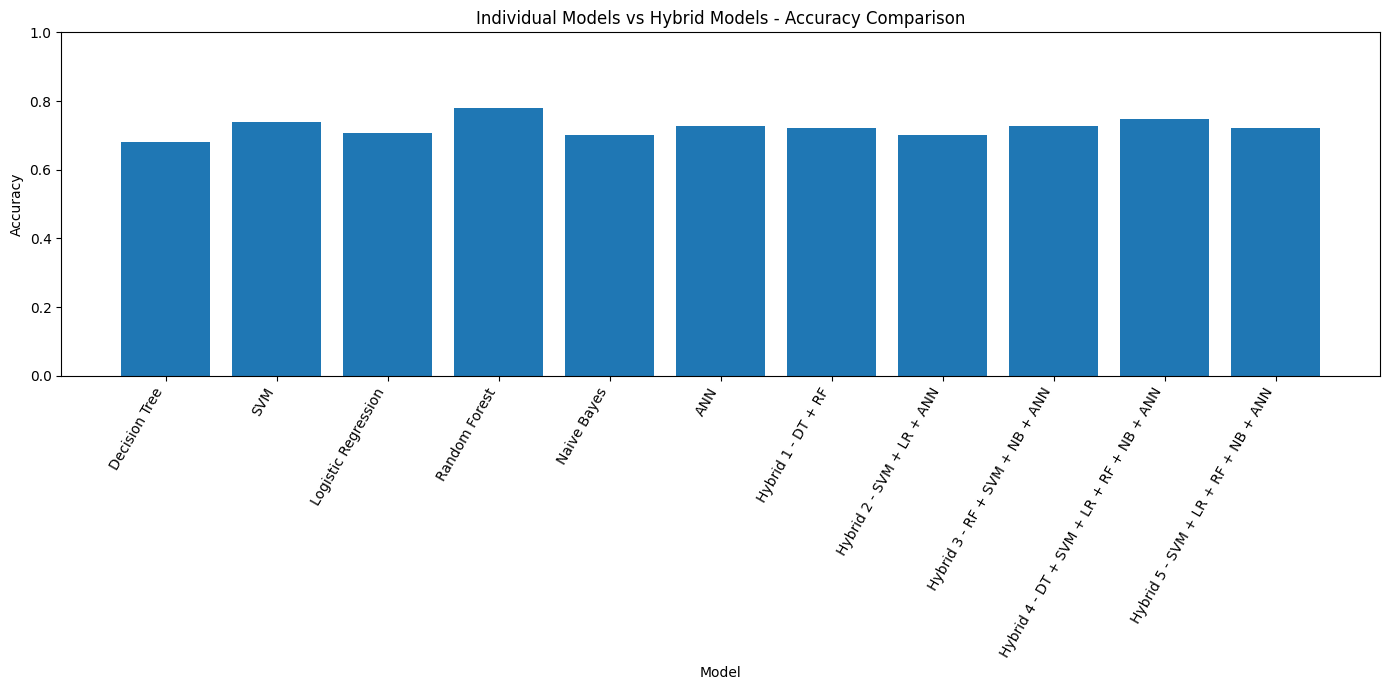

In [81]:
# ============================================================
# COMPARISON BAR CHART
# ============================================================

plt.figure(figsize=(14, 7))
plt.bar(all_results_df["Model"], all_results_df["Accuracy"])
plt.xticks(rotation=60, ha="right")
plt.ylabel("Accuracy")
plt.xlabel("Model")
plt.title("Individual Models vs Hybrid Models - Accuracy Comparison")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

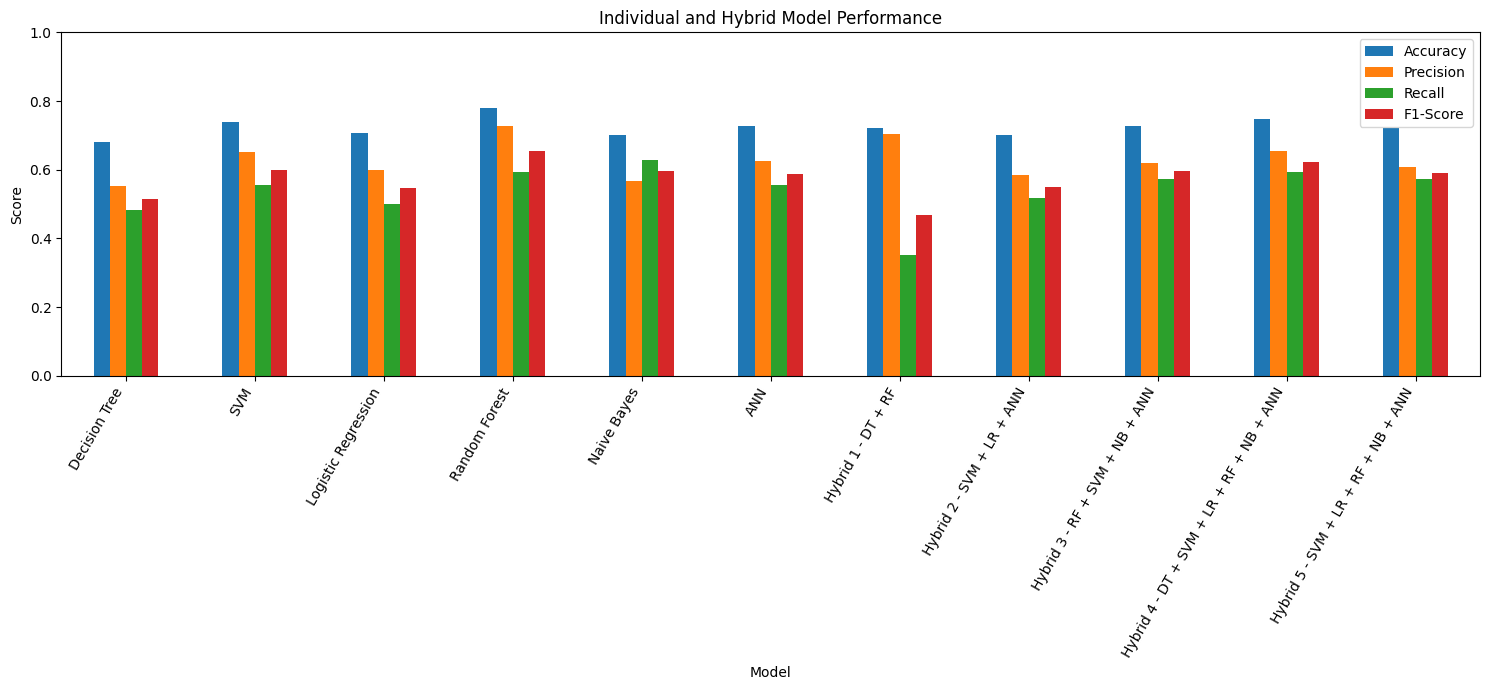

In [82]:
# ============================================================
# ALL METRICS COMPARISON
# ============================================================

metrics_to_plot = ["Accuracy", "Precision", "Recall", "F1-Score"]

ax = all_results_df.set_index("Model")[metrics_to_plot].plot(
    kind="bar",
    figsize=(15, 7)
)

plt.ylabel("Score")
plt.title("Individual and Hybrid Model Performance")
plt.ylim(0, 1)
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()

## Confusion Matrices for the Four Hybrid Models

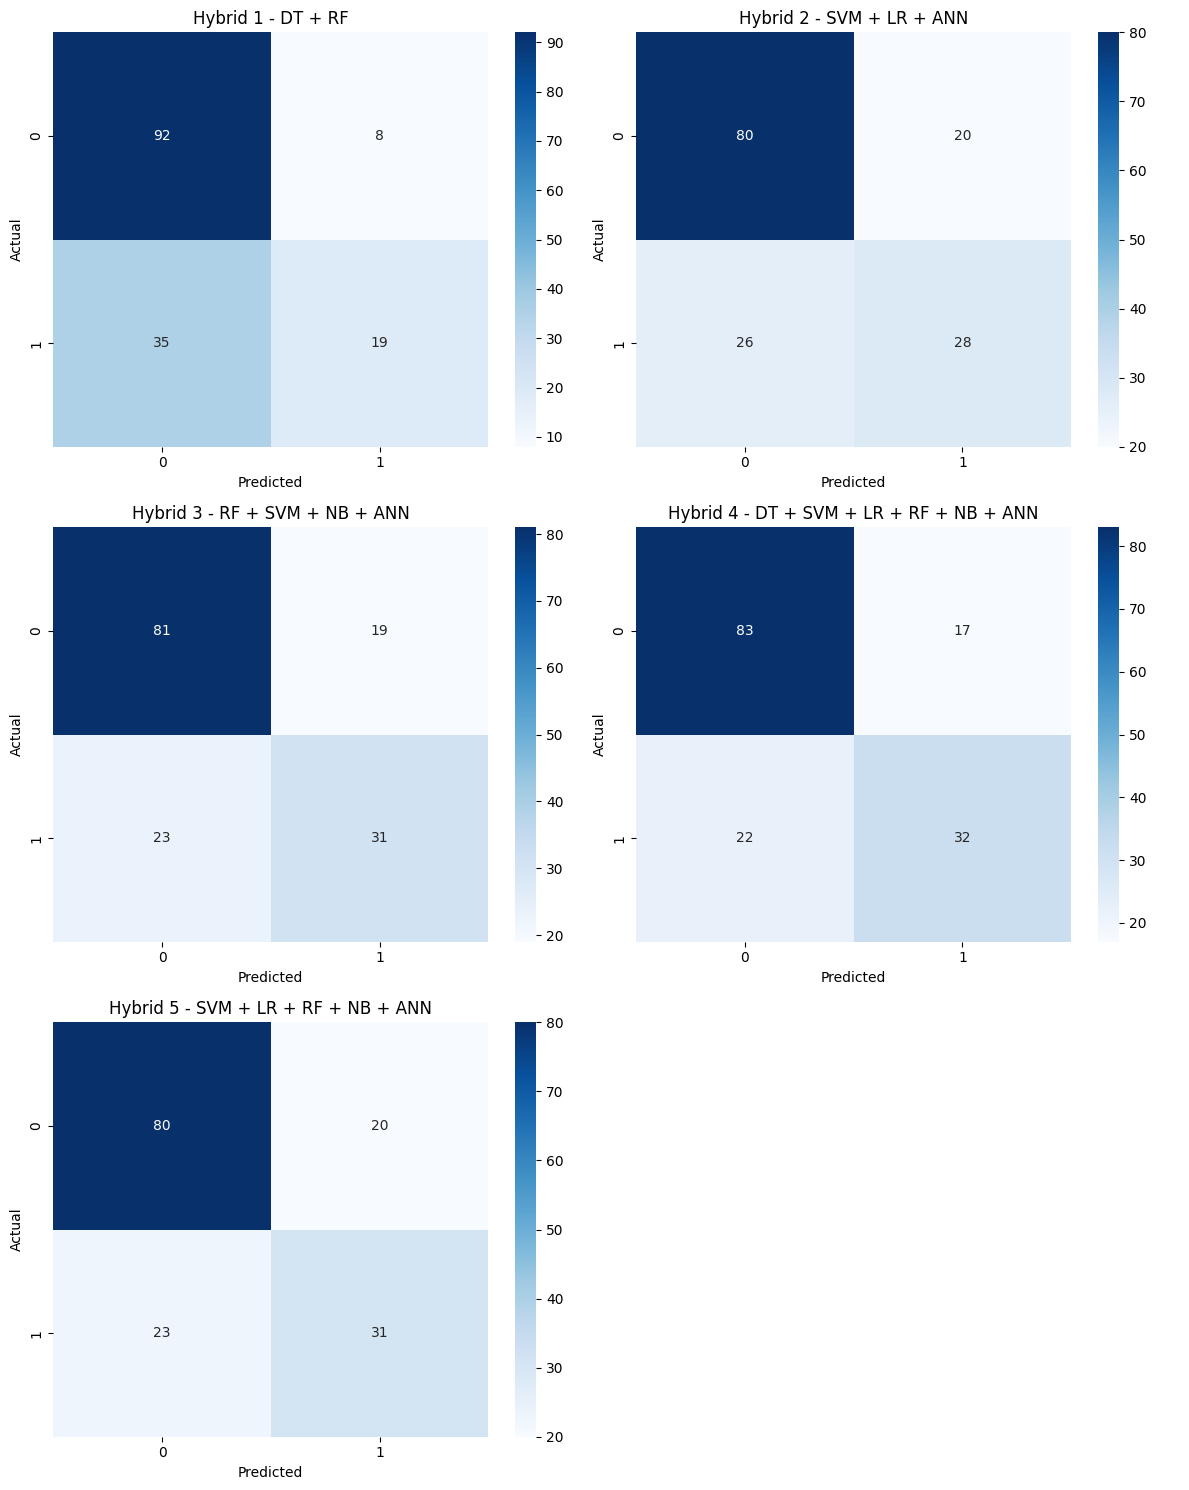

In [83]:
# ============================================================
# CONFUSION MATRICES - HYBRID MODELS
# ============================================================

hybrid_predictions = {
    "Hybrid 1 - DT + RF": hybrid1_pred,
    "Hybrid 2 - SVM + LR + ANN": hybrid2_pred,
    "Hybrid 3 - RF + SVM + NB + ANN": hybrid3_pred,
    "Hybrid 4 - DT + SVM + LR + RF + NB + ANN": hybrid4_pred,
    "Hybrid 5 - SVM + LR + RF + NB + ANN": hybrid5_pred
}

fig, axes = plt.subplots(3, 2, figsize=(12, 15))
axes = axes.ravel()

for ax, (name, pred) in zip(axes, hybrid_predictions.items()):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax)
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

# Hide unused sixth panel
axes[-1].axis("off")

plt.tight_layout()
plt.show()


## ROC Curves

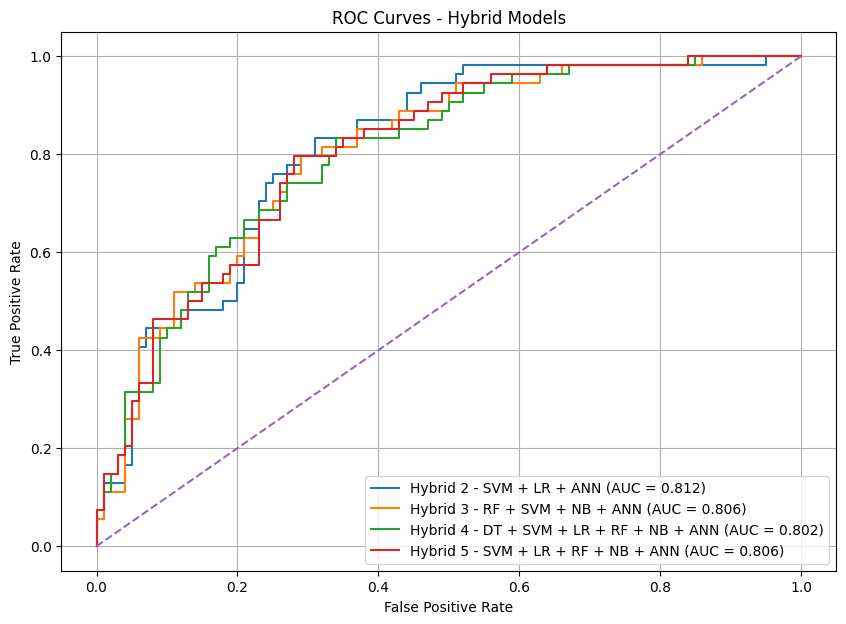

In [84]:
# ============================================================
# ROC CURVES FOR HYBRID MODELS
# ============================================================

roc_models = {
    "Hybrid 2 - SVM + LR + ANN": hybrid2_prob,
    "Hybrid 3 - RF + SVM + NB + ANN": hybrid3_prob,
    "Hybrid 4 - DT + SVM + LR + RF + NB + ANN": hybrid4_prob,
    "Hybrid 5 - SVM + LR + RF + NB + ANN": hybrid5_prob
}

plt.figure(figsize=(10, 7))

for name, prob in roc_models.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    auc_value = roc_auc_score(y_test, prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc_value:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves - Hybrid Models")
plt.legend()
plt.grid(True)
plt.show()


## Final Model Selection and Patient Prediction

In [85]:
# ============================================================
# SELECT MODEL BY ACCURACY
# ============================================================

comparison_for_selection = all_results_df.copy()
comparison_for_selection["Accuracy"] = pd.to_numeric(
    comparison_for_selection["Accuracy"],
    errors="coerce"
)

best_row = comparison_for_selection.loc[
    comparison_for_selection["Accuracy"].idxmax()
]

print("Best model according to test-set accuracy:")
print(best_row["Model"])
print("Accuracy:", round(best_row["Accuracy"], 4))

Best model according to test-set accuracy:
Random Forest
Accuracy: 0.7792


In [86]:
# ============================================================
# HYBRID PATIENT-LEVEL PREDICTIONS
# ============================================================

prediction_df_hybrid = pd.DataFrame({
    "Actual": y_test.values,
    "Hybrid 1": hybrid1_pred,
    "Hybrid 2": hybrid2_pred,
    "Hybrid 3": hybrid3_pred,
    "Hybrid 4": hybrid4_pred,
    "Hybrid 5": hybrid5_pred
})

display(prediction_df_hybrid.head(20))

print("Hybrid 4 Correct Predictions:",
      (prediction_df_hybrid["Actual"] == prediction_df_hybrid["Hybrid 4"]).sum())
print("Hybrid 4 Incorrect Predictions:",
      (prediction_df_hybrid["Actual"] != prediction_df_hybrid["Hybrid 4"]).sum())
print("Hybrid 5 Correct Predictions:",
      (prediction_df_hybrid["Actual"] == prediction_df_hybrid["Hybrid 5"]).sum())
print("Hybrid 5 Incorrect Predictions:",
      (prediction_df_hybrid["Actual"] != prediction_df_hybrid["Hybrid 5"]).sum())


,Actual,Hybrid 1,Hybrid 2,Hybrid 3,Hybrid 4,Hybrid 5
0,0,1,1,1,1,1
1,0,0,0,0,0,0
2,0,0,0,0,0,0
3,1,0,0,0,0,0
4,0,0,0,0,0,0
5,0,0,0,0,0,0
6,1,0,0,0,0,1
7,1,1,1,1,1,1
8,0,0,0,0,0,0
9,0,1,1,1,1,1


Hybrid 4 Correct Predictions: 115
Hybrid 4 Incorrect Predictions: 39
Hybrid 5 Correct Predictions: 111
Hybrid 5 Incorrect Predictions: 43


In [87]:
# ============================================================
# SAVE FINAL COMPARISON TABLE
# ============================================================

all_results_df.to_csv(
    "diabetes_model_comparison_individual_and_hybrid.csv",
    index=False
)

print("Comparison file saved successfully.")

Comparison file saved successfully.


## PHASE 3 - PSO BASED HYPERPARAMETER OPTIMIZATION

In [88]:
# ============================================================
# PHASE 3 - PARTICLE SWARM OPTIMIZATION (IMPROVED)
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report
)

def pso_optimize(
    objective_function,
    bounds,
    n_particles=16,
    n_iterations=20,
    random_state=42
):
    """PSO with linearly decreasing inertia for better exploration/exploitation."""
    rng = np.random.default_rng(random_state)
    lower_bounds = np.array([b[0] for b in bounds], dtype=float)
    upper_bounds = np.array([b[1] for b in bounds], dtype=float)
    n_dimensions = len(bounds)

    positions = rng.uniform(
        lower_bounds, upper_bounds,
        size=(n_particles, n_dimensions)
    )
    velocities = np.zeros_like(positions)
    personal_best_positions = positions.copy()
    personal_best_scores = np.array([
        objective_function(position) for position in positions
    ])

    best_index = np.argmax(personal_best_scores)
    global_best_position = personal_best_positions[best_index].copy()
    global_best_score = personal_best_scores[best_index]
    convergence_history = [global_best_score]

    for iteration in range(n_iterations):
        # High inertia early = exploration; lower inertia later = exploitation
        inertia = 0.9 - (0.5 * iteration / max(1, n_iterations - 1))

        for i in range(n_particles):
            r1 = rng.random(n_dimensions)
            r2 = rng.random(n_dimensions)

            velocities[i] = (
                inertia * velocities[i]
                + 1.5 * r1 * (personal_best_positions[i] - positions[i])
                + 1.5 * r2 * (global_best_position - positions[i])
            )

            positions[i] = np.clip(
                positions[i] + velocities[i],
                lower_bounds, upper_bounds
            )

            score = objective_function(positions[i])

            if score > personal_best_scores[i]:
                personal_best_scores[i] = score
                personal_best_positions[i] = positions[i].copy()

                if score > global_best_score:
                    global_best_score = score
                    global_best_position = positions[i].copy()

        convergence_history.append(global_best_score)
        print(
            f"Iteration {iteration + 1}/{n_iterations}"
            f" | Inertia: {inertia:.3f}"
            f" | Best CV Accuracy: {global_best_score:.4f}"
        )

    return global_best_position, global_best_score, convergence_history


svm +pso

In [89]:
# ============================================================
# SVM + PSO
# ============================================================

print("=" * 60)
print("SVM + PSO OPTIMIZATION")
print("=" * 60)


# ============================================================
# SVM OBJECTIVE FUNCTION
# ============================================================

def svm_pso_objective(position):

    # PSO searches logarithmic values
    C = 10 ** position[0]
    gamma = 10 ** position[1]

    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    scores = []

    for train_index, validation_index in cv.split(
        X_train,
        y_train
    ):

        X_cv_train = X_train.iloc[
            train_index
        ]

        X_cv_val = X_train.iloc[
            validation_index
        ]

        y_cv_train = y_train.iloc[
            train_index
        ]

        y_cv_val = y_train.iloc[
            validation_index
        ]

        # Scaling is inside the CV pipeline
        svm_pipeline = Pipeline([
            (
                "scaler",
                StandardScaler()
            ),
            (
                "svm",
                SVC(
                    C=C,
                    gamma=gamma,
                    kernel="rbf",
                    random_state=42
                )
            )
        ])

        svm_pipeline.fit(
            X_cv_train,
            y_cv_train
        )

        prediction = svm_pipeline.predict(
            X_cv_val
        )

        score = accuracy_score(
            y_cv_val,
            prediction
        )

        scores.append(score)

    return np.mean(scores)


# ============================================================
# SVM SEARCH SPACE
# ============================================================

svm_bounds = [
    (-2, 3),     # log10(C)     -> 0.01 to 1000
    (-4, 1)      # log10(gamma) -> 0.0001 to 10
]


# ============================================================
# RUN PSO
# ============================================================

(
    svm_best_position,
    svm_best_cv_accuracy,
    svm_convergence
) = pso_optimize(
    objective_function=svm_pso_objective,
    bounds=svm_bounds,
    n_particles=16,
    n_iterations=20,
    random_state=42
)


# Convert optimized values
svm_best_C = 10 ** svm_best_position[0]
svm_best_gamma = 10 ** svm_best_position[1]


print("\nBest SVM Parameters")
print("-" * 40)

print(
    "C     :",
    svm_best_C
)

print(
    "Gamma :",
    svm_best_gamma
)

print(
    "Best 5-Fold CV Accuracy:",
    svm_best_cv_accuracy
)


SVM + PSO OPTIMIZATION
Iteration 1/20 | Inertia: 0.900 | Best CV Accuracy: 0.7931
Iteration 2/20 | Inertia: 0.874 | Best CV Accuracy: 0.7931
Iteration 3/20 | Inertia: 0.847 | Best CV Accuracy: 0.7931
Iteration 4/20 | Inertia: 0.821 | Best CV Accuracy: 0.7931
Iteration 5/20 | Inertia: 0.795 | Best CV Accuracy: 0.7931
Iteration 6/20 | Inertia: 0.768 | Best CV Accuracy: 0.7931
Iteration 7/20 | Inertia: 0.742 | Best CV Accuracy: 0.7931
Iteration 8/20 | Inertia: 0.716 | Best CV Accuracy: 0.7931
Iteration 9/20 | Inertia: 0.689 | Best CV Accuracy: 0.7931
Iteration 10/20 | Inertia: 0.663 | Best CV Accuracy: 0.7947
Iteration 11/20 | Inertia: 0.637 | Best CV Accuracy: 0.7947
Iteration 12/20 | Inertia: 0.611 | Best CV Accuracy: 0.7947
Iteration 13/20 | Inertia: 0.584 | Best CV Accuracy: 0.7947
Iteration 14/20 | Inertia: 0.558 | Best CV Accuracy: 0.7947
Iteration 15/20 | Inertia: 0.532 | Best CV Accuracy: 0.7947
Iteration 16/20 | Inertia: 0.505 | Best CV Accuracy: 0.7947
Iteration 17/20 | Inertia:

final SVM + PSO

In [90]:
# ============================================================
# FINAL SVM + PSO MODEL
# ============================================================

svm_pso_model = SVC(
    C=svm_best_C,
    gamma=svm_best_gamma,
    kernel="rbf",
    probability=True,
    random_state=42
)


# Train using the complete training data
svm_pso_model.fit(
    X_train_scaled,
    y_train
)


# Prediction
svm_pso_pred = svm_pso_model.predict(
    X_test_scaled
)


# Probability
svm_pso_prob = svm_pso_model.predict_proba(
    X_test_scaled
)[:, 1]


# ============================================================
# METRICS
# ============================================================

svm_pso_accuracy = accuracy_score(
    y_test,
    svm_pso_pred
)

svm_pso_precision = precision_score(
    y_test,
    svm_pso_pred,
    zero_division=0
)

svm_pso_recall = recall_score(
    y_test,
    svm_pso_pred,
    zero_division=0
)

svm_pso_f1 = f1_score(
    y_test,
    svm_pso_pred,
    zero_division=0
)

svm_pso_auc = roc_auc_score(
    y_test,
    svm_pso_prob
)


print("\n" + "=" * 60)
print("SVM + PSO FINAL RESULTS")
print("=" * 60)

print(
    "Accuracy :",
    round(svm_pso_accuracy, 4)
)

print(
    "Precision:",
    round(svm_pso_precision, 4)
)

print(
    "Recall   :",
    round(svm_pso_recall, 4)
)

print(
    "F1 Score:",
    round(svm_pso_f1, 4)
)

print(
    "ROC-AUC  :",
    round(svm_pso_auc, 4)
)

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        svm_pso_pred
    )
)


SVM + PSO FINAL RESULTS
Accuracy : 0.7013
Precision: 0.5909
Recall   : 0.4815
F1 Score: 0.5306
ROC-AUC  : 0.8169

Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.82      0.78       100
           1       0.59      0.48      0.53        54

    accuracy                           0.70       154
   macro avg       0.67      0.65      0.66       154
weighted avg       0.69      0.70      0.69       154



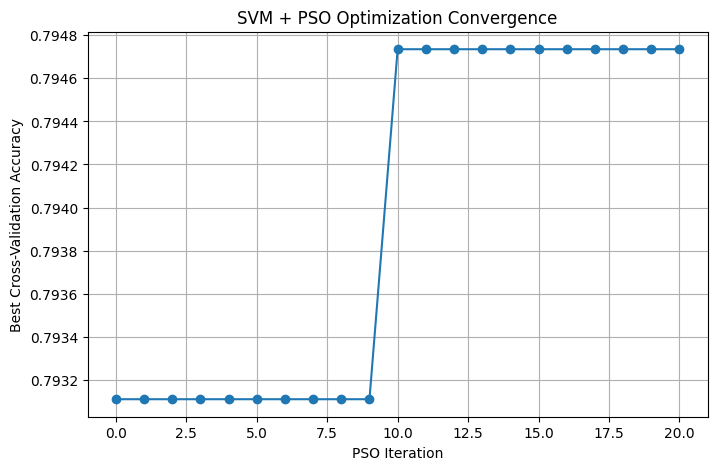

In [91]:
# ============================================================
# SVM + PSO CONVERGENCE
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    range(len(svm_convergence)),
    svm_convergence,
    marker="o"
)

plt.xlabel("PSO Iteration")
plt.ylabel("Best Cross-Validation Accuracy")
plt.title("SVM + PSO Optimization Convergence")

plt.grid(True)
plt.show()

#Random Forest + PSO

In [92]:
# ============================================================
# RANDOM FOREST + PSO - 25 ITERATIONS
# ============================================================

print("=" * 60)
print("RANDOM FOREST + PSO OPTIMIZATION")
print("=" * 60)


# ============================================================
# RANDOM FOREST OBJECTIVE FUNCTION
# ============================================================

def rf_pso_objective(position):

    n_estimators = int(
        round(position[0])
    )

    max_depth = int(
        round(position[1])
    )

    min_samples_split = int(
        round(position[2])
    )

    min_samples_leaf = int(
        round(position[3])
    )

    max_features = float(
        position[4]
    )

    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    scores = []

    for train_index, validation_index in cv.split(
        X_train,
        y_train
    ):

        X_cv_train = X_train.iloc[
            train_index
        ]

        X_cv_val = X_train.iloc[
            validation_index
        ]

        y_cv_train = y_train.iloc[
            train_index
        ]

        y_cv_val = y_train.iloc[
            validation_index
        ]

        rf_model = RandomForestClassifier(
            n_estimators=n_estimators,
            max_depth=max_depth,
            min_samples_split=min_samples_split,
            min_samples_leaf=min_samples_leaf,
            max_features=max_features,
            random_state=42,
            n_jobs=-1
        )

        rf_model.fit(
            X_cv_train,
            y_cv_train
        )

        prediction = rf_model.predict(
            X_cv_val
        )

        score = accuracy_score(
            y_cv_val,
            prediction
        )

        scores.append(score)

    return np.mean(scores)


# ============================================================
# RANDOM FOREST SEARCH SPACE
# ============================================================

rf_bounds = [
    (100, 500),  # n_estimators
    (3, 30),     # max_depth
    (2, 20),     # min_samples_split
    (1, 8),      # min_samples_leaf
    (0.4, 1.0)   # max_features
]


# ============================================================
# RUN PSO - 25 ITERATIONS
# ============================================================

(
    rf_best_position,
    rf_best_cv_accuracy,
    rf_convergence
) = pso_optimize(
    objective_function=rf_pso_objective,
    bounds=rf_bounds,
    n_particles=16,
    n_iterations=25,
    random_state=42
)


# ============================================================
# CONVERT BEST POSITION TO RF PARAMETERS
# ============================================================

rf_best_n_estimators = int(
    round(rf_best_position[0])
)

rf_best_max_depth = int(
    round(rf_best_position[1])
)

rf_best_min_samples_split = int(
    round(rf_best_position[2])
)

rf_best_min_samples_leaf = int(
    round(rf_best_position[3])
)

rf_best_max_features = float(
    rf_best_position[4]
)


# ============================================================
# DISPLAY BEST PARAMETERS
# ============================================================

print("\n")
print("=" * 60)
print("BEST RANDOM FOREST PARAMETERS")
print("=" * 60)

print(
    "n_estimators:",
    rf_best_n_estimators
)

print(
    "max_depth:",
    rf_best_max_depth
)

print(
    "min_samples_split:",
    rf_best_min_samples_split
)

print(
    "min_samples_leaf:",
    rf_best_min_samples_leaf
)

print(
    "max_features:",
    rf_best_max_features
)

print(
    "Best 5-Fold CV Accuracy:",
    rf_best_cv_accuracy
)

print(
    "Best 5-Fold CV Accuracy (%):",
    round(
        rf_best_cv_accuracy * 100,
        2
    )
)


RANDOM FOREST + PSO OPTIMIZATION
Iteration 1/25 | Inertia: 0.900 | Best CV Accuracy: 0.7785
Iteration 2/25 | Inertia: 0.879 | Best CV Accuracy: 0.7785
Iteration 3/25 | Inertia: 0.858 | Best CV Accuracy: 0.7785
Iteration 4/25 | Inertia: 0.838 | Best CV Accuracy: 0.7785
Iteration 5/25 | Inertia: 0.817 | Best CV Accuracy: 0.7785
Iteration 6/25 | Inertia: 0.796 | Best CV Accuracy: 0.7801
Iteration 7/25 | Inertia: 0.775 | Best CV Accuracy: 0.7818
Iteration 8/25 | Inertia: 0.754 | Best CV Accuracy: 0.7818
Iteration 9/25 | Inertia: 0.733 | Best CV Accuracy: 0.7818
Iteration 10/25 | Inertia: 0.713 | Best CV Accuracy: 0.7818
Iteration 11/25 | Inertia: 0.692 | Best CV Accuracy: 0.7818
Iteration 12/25 | Inertia: 0.671 | Best CV Accuracy: 0.7818
Iteration 13/25 | Inertia: 0.650 | Best CV Accuracy: 0.7834
Iteration 14/25 | Inertia: 0.629 | Best CV Accuracy: 0.7834
Iteration 15/25 | Inertia: 0.608 | Best CV Accuracy: 0.7834
Iteration 16/25 | Inertia: 0.588 | Best CV Accuracy: 0.7834
Iteration 17/25 

Train Final Random Forest + PSO

In [93]:
# ============================================================
# FINAL RANDOM FOREST + PSO MODEL
# ============================================================

rf_pso_model = RandomForestClassifier(
    n_estimators=rf_best_n_estimators,
    max_depth=rf_best_max_depth,
    min_samples_split=rf_best_min_samples_split,
    min_samples_leaf=rf_best_min_samples_leaf,
    max_features=rf_best_max_features,
    random_state=42,
    n_jobs=-1
)


# Random Forest does not require scaling
rf_pso_model.fit(
    X_train,
    y_train
)


# Prediction
rf_pso_pred = rf_pso_model.predict(
    X_test
)


# Probability
rf_pso_prob = rf_pso_model.predict_proba(
    X_test
)[:, 1]


# ============================================================
# METRICS
# ============================================================

rf_pso_accuracy = accuracy_score(
    y_test,
    rf_pso_pred
)

rf_pso_precision = precision_score(
    y_test,
    rf_pso_pred,
    zero_division=0
)

rf_pso_recall = recall_score(
    y_test,
    rf_pso_pred,
    zero_division=0
)

rf_pso_f1 = f1_score(
    y_test,
    rf_pso_pred,
    zero_division=0
)

rf_pso_auc = roc_auc_score(
    y_test,
    rf_pso_prob
)


print("\n" + "=" * 60)
print("RANDOM FOREST + PSO FINAL RESULTS")
print("=" * 60)

print(
    "Accuracy :",
    round(rf_pso_accuracy, 4)
)

print(
    "Precision:",
    round(rf_pso_precision, 4)
)

print(
    "Recall   :",
    round(rf_pso_recall, 4)
)

print(
    "F1 Score:",
    round(rf_pso_f1, 4)
)

print(
    "ROC-AUC  :",
    round(rf_pso_auc, 4)
)

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        rf_pso_pred
    )
)



RANDOM FOREST + PSO FINAL RESULTS
Accuracy : 0.7597
Precision: 0.6809
Recall   : 0.5926
F1 Score: 0.6337
ROC-AUC  : 0.8169

Classification Report:
              precision    recall  f1-score   support

           0       0.79      0.85      0.82       100
           1       0.68      0.59      0.63        54

    accuracy                           0.76       154
   macro avg       0.74      0.72      0.73       154
weighted avg       0.75      0.76      0.76       154



In [94]:
# ============================================================
# EDPA - BASE PAPER METHOD (EDPA-STYLE IMPLEMENTATION)
# ============================================================
# This implements an EDPA-style ensemble using the same
# preprocessed train/test data used in this project.
#
# Note:
# The base paper describes EDPA as an ensemble diabetic
# prediction method. The paper does not provide enough
# implementation detail to reproduce its exact internal
# ensemble construction, so this is an EDPA-style
# Random Forest approximation and should be reported as such.

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

print("=" * 60)
print("EDPA - ENSEMBLE DIABETIC PREDICTION ALGORITHM")
print("=" * 60)

edpa_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)

edpa_model.fit(X_train, y_train)

# Predictions and probabilities
edpa_pred = edpa_model.predict(X_test)
edpa_prob = edpa_model.predict_proba(X_test)[:, 1]

# ============================================================
# EDPA METRICS
# ============================================================

edpa_accuracy = accuracy_score(y_test, edpa_pred)
edpa_precision = precision_score(y_test, edpa_pred, zero_division=0)
edpa_recall = recall_score(y_test, edpa_pred, zero_division=0)
edpa_f1 = f1_score(y_test, edpa_pred, zero_division=0)
edpa_auc = roc_auc_score(y_test, edpa_prob)

print("\nEDPA Accuracy:", round(edpa_accuracy, 4))
print("EDPA Accuracy (%):", round(edpa_accuracy * 100, 2))
print("EDPA Precision:", round(edpa_precision, 4))
print("EDPA Recall:", round(edpa_recall, 4))
print("EDPA F1 Score:", round(edpa_f1, 4))
print("EDPA ROC-AUC:", round(edpa_auc, 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    edpa_pred,
    target_names=["Non-Diabetic", "Diabetic"],
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, edpa_pred))


EDPA - ENSEMBLE DIABETIC PREDICTION ALGORITHM

EDPA Accuracy: 0.7792
EDPA Accuracy (%): 77.92
EDPA Precision: 0.7273
EDPA Recall: 0.5926
EDPA F1 Score: 0.6531
EDPA ROC-AUC: 0.8192

Classification Report:
              precision    recall  f1-score   support

Non-Diabetic       0.80      0.88      0.84       100
    Diabetic       0.73      0.59      0.65        54

    accuracy                           0.78       154
   macro avg       0.76      0.74      0.75       154
weighted avg       0.77      0.78      0.77       154


Confusion Matrix:
[[88 12]
 [22 32]]


## Class-wise Accuracy (Non-Diabetic and Diabetic)

Note: for each class, the class-wise correct rate is the class recall. The overall accuracy is reported separately.


### Why PSO Cross-Validation Accuracy Can Be Higher Than Final Test Accuracy

The **Best 5-Fold CV Accuracy** printed during PSO is calculated only from the **training set**, using 5-fold cross-validation to select hyperparameters. The **Final Accuracy** is calculated later on the completely separate **20% test set** that PSO did not use for parameter selection.

Therefore, values such as **78% CV accuracy and 73% test accuracy are not contradictory**. They measure performance on different data. A lower test accuracy can occur because the selected hyperparameters generalize less well to the unseen test set.

For the research report, keep both numbers but describe them separately as **best 5-fold cross-validation accuracy during optimization** and **independent test-set accuracy**.

In [95]:
# ============================================================
# CLASS-WISE METRICS
# ============================================================

from sklearn.metrics import classification_report

model_predictions = {
    "Decision Tree": dt_pred,
    "SVM": svm_pred,
    "Logistic Regression": lr_pred,
    "Random Forest": rf_pred,
    "Naive Bayes": nb_pred,
    "ANN": ann_pred,
    "Hybrid 1": hybrid1_pred,
    "Hybrid 2": hybrid2_pred,
    "Hybrid 3": hybrid3_pred,
    "Hybrid 4": hybrid4_pred,
    "Hybrid 5": hybrid5_pred,
    "SVM + PSO": svm_pso_pred,
    "Random Forest + PSO": rf_pso_pred,
    "EDPA-style RF approximation": edpa_pred
}

rows = []
for model_name, pred in model_predictions.items():
    report = classification_report(
        y_test, pred, output_dict=True, zero_division=0
    )
    rows.append({
        "Model": model_name,
        "Overall Accuracy": accuracy_score(y_test, pred),
        "Non-Diabetic Accuracy (Recall)": report["0"]["recall"],
        "Diabetic Accuracy (Recall)": report["1"]["recall"],
        "Macro F1": report["macro avg"]["f1-score"],
        "Weighted F1": report["weighted avg"]["f1-score"]
    })

classwise_results_df = pd.DataFrame(rows).sort_values(
    "Overall Accuracy", ascending=False
)
display(classwise_results_df.round(4))


,Model,Overall Accuracy,Non-Diabetic Accuracy (Recall),Diabetic Accuracy (Recall),Macro F1,Weighted F1
3,Random Forest,0.7792,0.88,0.5926,0.7456,0.7732
13,EDPA-style RF approximation,0.7792,0.88,0.5926,0.7456,0.7732
12,Random Forest + PSO,0.7597,0.85,0.5926,0.7275,0.7555
9,Hybrid 4,0.7468,0.83,0.5926,0.7156,0.7437
1,SVM,0.7403,0.84,0.5556,0.7038,0.7349
5,ANN,0.7273,0.82,0.5556,0.6922,0.7232
8,Hybrid 3,0.7273,0.81,0.5741,0.6951,0.7247
10,Hybrid 5,0.7208,0.80,0.5741,0.6893,0.7189
6,Hybrid 1,0.7208,0.92,0.3519,0.6399,0.6908
2,Logistic Regression,0.7078,0.82,0.5000,0.6651,0.7008


Random Forest PSO Convergence

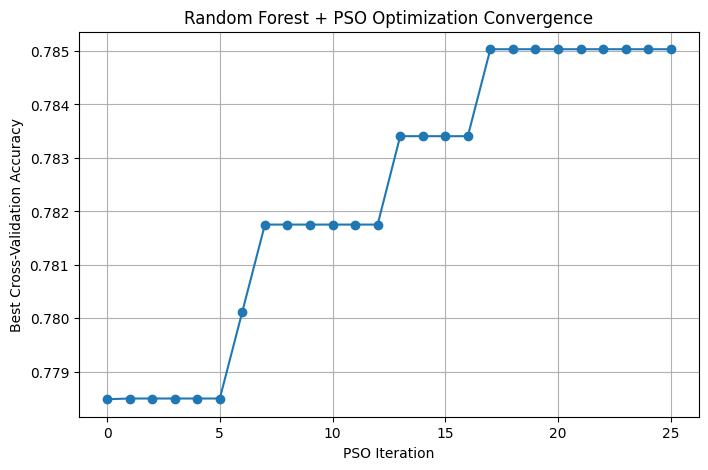

In [96]:
# ============================================================
# RANDOM FOREST + PSO CONVERGENCE
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    range(len(rf_convergence)),
    rf_convergence,
    marker="o"
)

plt.xlabel("PSO Iteration")
plt.ylabel("Best Cross-Validation Accuracy")
plt.title(
    "Random Forest + PSO Optimization Convergence"
)

plt.grid(True)
plt.show()

Combine the Two New PSO Models

In [97]:
# ============================================================
# PHASE 3 - PSO MODEL RESULTS
# ============================================================

pso_results = [

    {
        "Model": "SVM + PSO",
        "Accuracy": svm_pso_accuracy,
        "Precision": svm_pso_precision,
        "Recall": svm_pso_recall,
        "F1-Score": svm_pso_f1,
        "ROC-AUC": svm_pso_auc
    },

    {
        "Model": "Random Forest + PSO",
        "Accuracy": rf_pso_accuracy,
        "Precision": rf_pso_precision,
        "Recall": rf_pso_recall,
        "F1-Score": rf_pso_f1,
        "ROC-AUC": rf_pso_auc
    }
]


pso_results_df = pd.DataFrame(
    pso_results
)


print("=" * 60)
print("PSO MODEL RESULTS")
print("=" * 60)

display(
    pso_results_df.round(4)
)

PSO MODEL RESULTS


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,SVM + PSO,0.7013,0.5909,0.4815,0.5306,0.8169
1,Random Forest + PSO,0.7597,0.6809,0.5926,0.6337,0.8169


Comparision

In [98]:
# ============================================================
# PSO VS ORIGINAL MODELS
# ============================================================

# Find original model results
original_results_df = pd.DataFrame(
    results
).copy()


# Fix model column name if necessary
if "Model" not in original_results_df.columns:

    if "Algorithm" in original_results_df.columns:

        original_results_df = (
            original_results_df.rename(
                columns={
                    "Algorithm": "Model"
                }
            )
        )


# Fix F1 column name
if "F1 Score" in original_results_df.columns:

    original_results_df = (
        original_results_df.rename(
            columns={
                "F1 Score": "F1-Score"
            }
        )
    )


# Select original SVM and Random Forest
original_svm = original_results_df[
    original_results_df["Model"].str.contains(
        "SVM",
        case=False,
        na=False
    )
].copy()


original_rf = original_results_df[
    original_results_df["Model"].str.contains(
        "Random Forest",
        case=False,
        na=False
    )
].copy()


# Create comparison
base_vs_pso = pd.DataFrame({

    "Model": [
        "SVM",
        "SVM + PSO",
        "Random Forest",
        "Random Forest + PSO"
    ],

    "Accuracy": [
        original_svm.iloc[0]["Accuracy"],
        svm_pso_accuracy,
        original_rf.iloc[0]["Accuracy"],
        rf_pso_accuracy
    ]
})


print("=" * 60)
print("ORIGINAL VS PSO-OPTIMIZED MODELS")
print("=" * 60)

display(
    base_vs_pso.round(4)
)

ORIGINAL VS PSO-OPTIMIZED MODELS


,Model,Accuracy
0,SVM,0.7403
1,SVM + PSO,0.7013
2,Random Forest,0.7792
3,Random Forest + PSO,0.7597


In [99]:
# ============================================================
# ACCURACY IMPROVEMENT AFTER PSO
# ============================================================

svm_improvement = (
    svm_pso_accuracy
    - original_svm.iloc[0]["Accuracy"]
)

rf_improvement = (
    rf_pso_accuracy
    - original_rf.iloc[0]["Accuracy"]
)


print("=" * 60)
print("ACCURACY CHANGE AFTER PSO")
print("=" * 60)

print(
    "SVM original accuracy:",
    round(
        original_svm.iloc[0]["Accuracy"],
        4
    )
)

print(
    "SVM + PSO accuracy:",
    round(
        svm_pso_accuracy,
        4
    )
)

print(
    "SVM accuracy change:",
    round(
        svm_improvement,
        4
    )
)

print()

print(
    "Random Forest original accuracy:",
    round(
        original_rf.iloc[0]["Accuracy"],
        4
    )
)

print(
    "Random Forest + PSO accuracy:",
    round(
        rf_pso_accuracy,
        4
    )
)

print(
    "Random Forest accuracy change:",
    round(
        rf_improvement,
        4
    )
)

ACCURACY CHANGE AFTER PSO
SVM original accuracy: 0.7403
SVM + PSO accuracy: 0.7013
SVM accuracy change: -0.039

Random Forest original accuracy: 0.7792
Random Forest + PSO accuracy: 0.7597
Random Forest accuracy change: -0.0195


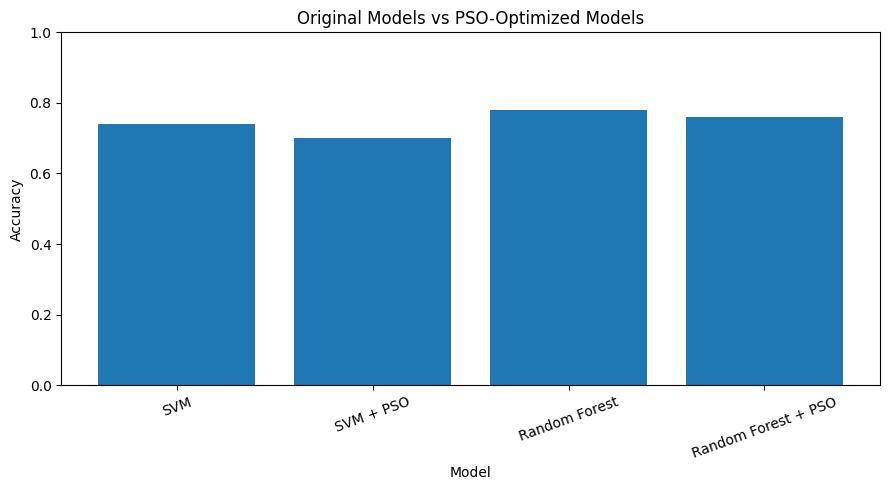

In [100]:
# ============================================================
# ORIGINAL VS PSO ACCURACY
# ============================================================

plt.figure(figsize=(9, 5))

plt.bar(
    base_vs_pso["Model"],
    base_vs_pso["Accuracy"]
)

plt.ylabel("Accuracy")
plt.xlabel("Model")
plt.title(
    "Original Models vs PSO-Optimized Models"
)

plt.ylim(0, 1)

plt.xticks(
    rotation=20
)

plt.tight_layout()
plt.show()

In [101]:
# ============================================================
# FINAL COMPARISON
# INDIVIDUAL + HYBRID + PSO + EDPA-STYLE MODELS
# ============================================================

# ------------------------------------------------------------
# Individual model results
# ------------------------------------------------------------

individual_results_final = pd.DataFrame(
    results
).copy()

# Fix model column
if "Model" not in individual_results_final.columns:
    if "Algorithm" in individual_results_final.columns:
        individual_results_final = individual_results_final.rename(
            columns={"Algorithm": "Model"}
        )

# Fix F1 column
if "F1 Score" in individual_results_final.columns:
    individual_results_final = individual_results_final.rename(
        columns={"F1 Score": "F1-Score"}
    )

# ------------------------------------------------------------
# Hybrid results
# ------------------------------------------------------------

hybrid_results_final = hybrid_results_df.copy()

# Fix model column
if "Model" not in hybrid_results_final.columns:
    if "Algorithm" in hybrid_results_final.columns:
        hybrid_results_final = hybrid_results_final.rename(
            columns={"Algorithm": "Model"}
        )

# Fix F1 column
if "F1 Score" in hybrid_results_final.columns:
    hybrid_results_final = hybrid_results_final.rename(
        columns={"F1 Score": "F1-Score"}
    )

# ------------------------------------------------------------
# PSO results
# ------------------------------------------------------------

pso_results_final = pso_results_df.copy()

# ------------------------------------------------------------
# EDPA-style result
# ------------------------------------------------------------
# The supplied base paper does not provide enough implementation
# detail for exact EDPA reproduction. Therefore this row is
# explicitly labeled as an EDPA-style Random Forest approximation.

edpa_results_df = pd.DataFrame([
    {
        "Model": "EDPA-style RF approximation",
        "Accuracy": edpa_accuracy,
        "Precision": edpa_precision,
        "Recall": edpa_recall,
        "F1-Score": edpa_f1,
        "ROC-AUC": edpa_auc
    }
])

# ------------------------------------------------------------
# Common metric columns
# ------------------------------------------------------------

metric_cols = [
    "Model",
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score",
    "ROC-AUC"
]

# Make sure all columns exist
for df_result in [
    individual_results_final,
    hybrid_results_final,
    pso_results_final,
    edpa_results_df
]:
    for col in metric_cols:
        if col not in df_result.columns:
            df_result[col] = np.nan

# ------------------------------------------------------------
# Combine everything
# ------------------------------------------------------------

final_results_df = pd.concat(
    [
        individual_results_final[metric_cols],
        hybrid_results_final[metric_cols],
        pso_results_final[metric_cols],
        edpa_results_df[metric_cols]
    ],
    ignore_index=True
)

print("=" * 70)
print("FINAL COMPARISON - ALL MODELS INCLUDING EDPA-STYLE APPROXIMATION")
print("=" * 70)

display(final_results_df.round(4))


FINAL COMPARISON - ALL MODELS INCLUDING EDPA-STYLE APPROXIMATION


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Decision Tree,0.6818,0.5532,0.4815,0.5149,0.6357
1,SVM,0.7403,0.6522,0.5556,0.6000,0.7964
2,Logistic Regression,0.7078,0.6000,0.5000,0.5455,0.8130
3,Random Forest,0.7792,0.7273,0.5926,0.6531,0.8192
4,Naive Bayes,0.7013,0.5667,0.6296,0.5965,0.7646
5,ANN,0.7273,0.6250,0.5556,0.5882,0.8087
6,Hybrid 1 - DT + RF,0.7208,0.7037,0.3519,0.4691,NaN
7,Hybrid 2 - SVM + LR + ANN,0.7013,0.5833,0.5185,0.5490,0.8119
8,Hybrid 3 - RF + SVM + NB + ANN,0.7273,0.6200,0.5741,0.5962,0.8065
9,Hybrid 4 - DT + SVM + LR + RF + NB + ANN,0.7468,0.6531,0.5926,0.6214,0.8019


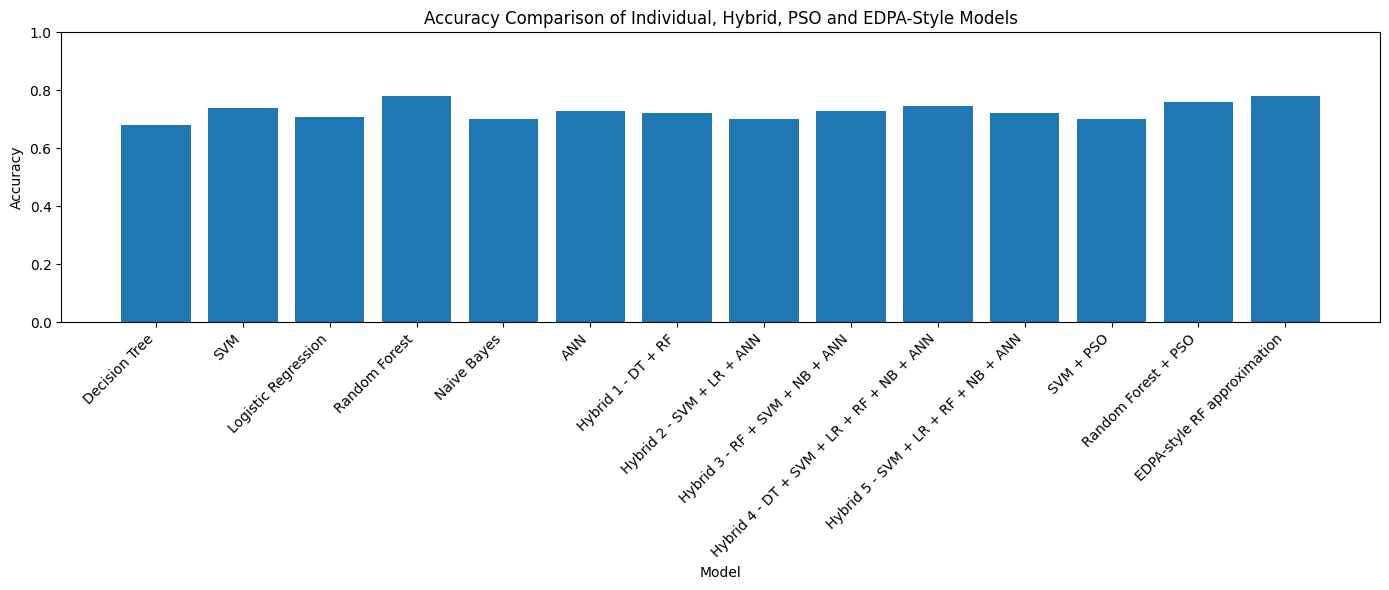

In [102]:
# ============================================================
# FINAL ACCURACY COMPARISON
# ============================================================

plt.figure(figsize=(14, 6))

plt.bar(
    final_results_df["Model"],
    final_results_df["Accuracy"]
)

plt.ylabel("Accuracy")
plt.xlabel("Model")
plt.title(
    "Accuracy Comparison of Individual, Hybrid, PSO and EDPA-Style Models"
)

plt.ylim(0, 1)

plt.xticks(
    rotation=45,
    ha="right"
)

plt.tight_layout()
plt.show()


In [103]:
# ============================================================
# FINAL RESULTS TABLE
# ============================================================

final_results_sorted = (
    final_results_df
    .sort_values(
        by="Accuracy",
        ascending=False
    )
    .reset_index(drop=True)
)

print("=" * 70)
print("FINAL MODEL PERFORMANCE TABLE")
print("Includes individual, hybrid, PSO and EDPA-style results")
print("=" * 70)

display(
    final_results_sorted.round(4)
)


FINAL MODEL PERFORMANCE TABLE
Includes individual, hybrid, PSO and EDPA-style results


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Random Forest,0.7792,0.7273,0.5926,0.6531,0.8192
1,EDPA-style RF approximation,0.7792,0.7273,0.5926,0.6531,0.8192
2,Random Forest + PSO,0.7597,0.6809,0.5926,0.6337,0.8169
3,Hybrid 4 - DT + SVM + LR + RF + NB + ANN,0.7468,0.6531,0.5926,0.6214,0.8019
4,SVM,0.7403,0.6522,0.5556,0.6000,0.7964
5,ANN,0.7273,0.6250,0.5556,0.5882,0.8087
6,Hybrid 3 - RF + SVM + NB + ANN,0.7273,0.6200,0.5741,0.5962,0.8065
7,Hybrid 5 - SVM + LR + RF + NB + ANN,0.7208,0.6078,0.5741,0.5905,0.8057
8,Hybrid 1 - DT + RF,0.7208,0.7037,0.3519,0.4691,NaN
9,Logistic Regression,0.7078,0.6000,0.5000,0.5455,0.8130


In [104]:
# ============================================================
# HIGHEST TEST ACCURACY
# ============================================================

best_accuracy_row = final_results_df.loc[
    final_results_df["Accuracy"].idxmax()
]


print("=" * 60)
print("HIGHEST TEST ACCURACY IN CURRENT EXPERIMENT")
print("=" * 60)

print(
    "Model:",
    best_accuracy_row["Model"]
)

print(
    "Accuracy:",
    round(
        best_accuracy_row["Accuracy"],
        4
    )
)

print(
    "Accuracy (%):",
    round(
        best_accuracy_row["Accuracy"] * 100,
        2
    )
)

HIGHEST TEST ACCURACY IN CURRENT EXPERIMENT
Model: Random Forest
Accuracy: 0.7792
Accuracy (%): 77.92


In [105]:
# ============================================================
# SAVE FINAL COMPARISON TABLE
# ============================================================

final_results_df.to_csv(
    "final_model_comparison.csv",
    index=False
)

print(
    "Final comparison saved as "
    "final_model_comparison.csv"
)
print("EDPA-style RF approximation is included in the saved table.")


Final comparison saved as final_model_comparison.csv
EDPA-style RF approximation is included in the saved table.
